# Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import base64

In [2]:
import ratinabox
from ratinabox.Environment import Environment
from ratinabox.Agent import Agent
from ratinabox.Neurons import FieldOfViewOVCs
# from ratinabox.Neurons import PlaceCells, GridCells #...

## aux funcs

In [3]:
import random
import string

def generate_random_string(n):
    """
    Generate a random string of length n.

    Parameters:
    n (int): The desired length of the string.

    Returns:
    str: A random string of length n.
    """
    if n <= 0:
        raise ValueError("Length 'n' must be a positive integer.")

    # Combine letters, digits, and punctuation
    characters = string.ascii_uppercase
    
    # Generate a random string of length n
    random_string = ''.join(random.choices(characters, k=n))

    return random_string


In [4]:
generate_random_string(8)

'MJTKHWDN'

In [5]:
def generate_all_positions_on_env(hole=None):

        # Define the range and step size
    step = 0.001  # Adjust the step size for granularity
    x_range = np.arange(0, 1 + step, step)
    y_range = np.arange(0, 1 + step, step)

    # Create a grid of (x, y) positions
    x, y = np.meshgrid(x_range, y_range)
    positions = np.column_stack([x.ravel(), y.ravel()])

    # Convert to a pandas DataFrame
    df_positions = pd.DataFrame(positions, columns=["X", "Y"])
    # df_positions['is_valid'] = [int(is_point_valid(pos, hole)) for pos in positions]
    df_positions['pos'] = [val for val in positions]

    return df_positions

In [6]:
def get_euclidean_distance(pos1, pos2):
    return np.sqrt((pos1[0] - pos2[0])**2 + ((pos1[1] - pos2[1])**2))
def apply_eucd_dist(x, obj=9):
    return get_euclidean_distance(x['pos'], x[f'obj_{obj}_pos'])

In [7]:
def gerar_grade_quadrada(n):
    """
    Gera uma lista de pontos (x, y) uniformemente distribuídos
    em uma grade quadrada dentro do domínio [0, 1] x [0, 1].

    Parâmetros:
        n (int): número de divisões por eixo (resultando em n x n pontos)

    Retorna:
        lista de tuplas (x, y)
    """
    pontos = []
    passo = 1.0 / (n - 1)  # para incluir o ponto 1.0 no final

    for i in range(n):
        x = i * passo
        for j in range(n):
            y = j * passo
            pontos.append((x, y))
    
    return pontos

In [8]:
def gerar_grade_com_ruido(n, sigma=0.02):
    """
    Gera uma grade com n x n pontos (x, y) dentro do domínio [0, 1] x [0, 1],
    adicionando ruído gaussiano positivo ou negativo aos pontos,
    mas mantendo-os dentro dos limites do domínio.

    Parâmetros:
        n (int): número de divisões por eixo
        sigma (float): desvio padrão do ruído

    Retorna:
        lista de tuplas (x, y)
    """
    pontos = []
    passo = 1.0 / (n - 1)

    for i in range(n):
        x_base = i * passo
        for j in range(n):
            y_base = j * passo

            # Ruído gaussiano (positivo ou negativo)
            ruido_x = random.gauss(0, sigma)
            ruido_y = random.gauss(0, sigma)

            x = min(max(0.0, x_base + ruido_x), 1.0)
            y = min(max(0.0, y_base + ruido_y), 1.0)

            pontos.append((x, y))
    
    return pontos

## Define EnV

In [9]:
Env = Environment(params={
    'aspect':1,
    # 'holes' : [[[0.4,0.2],[0.6,0.2],[0.6,0.8],[0.4,0.8]]],
    })

### Num of Cues

In [10]:
Env.has_holes

False

### RUN PARAMETERS

In [11]:
CUE_NAME_LEN = 4
MAX_NUMBER_OF_CUES = 5
# CONTEXT_LEN = MAX_NUMBER_OF_CUES*CUE_NAME_LEN
# CONTEXT_LEN

### gerando cues positions

In [12]:
CUES_LIST = gerar_grade_com_ruido(5, )

In [13]:
CUES_LIST

[(0.008990736153040144, 0.0),
 (0.0, 0.2561640733805774),
 (0.0, 0.46830458043202294),
 (0.0, 0.732977064731515),
 (0.0, 0.9902848026174408),
 (0.20749072430199844, 0.0),
 (0.26947624141112997, 0.25850604642328817),
 (0.2980403857116741, 0.5354458134189739),
 (0.22032011469284046, 0.750713315311565),
 (0.23717737376205317, 1.0),
 (0.5081632356501669, 0.0),
 (0.4641052880955634, 0.2757294221806029),
 (0.5248019101587034, 0.5349146171498323),
 (0.5120705165444741, 0.7653781542522785),
 (0.5204449599345465, 0.9735289568416922),
 (0.7484192860399256, 0.01353260393049755),
 (0.7774604479492981, 0.2524853208557481),
 (0.7314230189664931, 0.5309107332786459),
 (0.7314564874293784, 0.7135821608113108),
 (0.7271542170693643, 0.9855658276682336),
 (1.0, 0.0),
 (0.9931508497210669, 0.24456097913396596),
 (1.0, 0.5218867633757355),
 (0.958424659933497, 0.7533259341616082),
 (1.0, 1.0)]

In [14]:
NUM_OF_CUES = len(CUES_LIST)
NUM_OF_CUES

25

In [15]:
# CUES_LIST = []
# num_test = 0
# for i in range(NUM_OF_CUES):
#     candidate_point = np.random.rand(), np.random.rand()
#     CUES_LIST.append(candidate_point)
# print(f'{NUM_OF_CUES} cues criadas com {num_test} candidatos')

### gerando all positions df

In [16]:
apd = pd.read_parquet('apd_full.gzip')

In [17]:
apd.columns

Index(['X', 'Y', 'pos', 'obj_0_pos', 'obj_0_name', 'obj_1_pos', 'obj_1_name',
       'obj_2_pos', 'obj_2_name', 'obj_3_pos', 'obj_3_name', 'obj_4_pos',
       'obj_4_name', 'obj_5_pos', 'obj_5_name', 'obj_6_pos', 'obj_6_name',
       'obj_7_pos', 'obj_7_name', 'obj_8_pos', 'obj_8_name', 'obj_9_pos',
       'obj_9_name', 'obj_10_pos', 'obj_10_name', 'obj_11_pos', 'obj_11_name',
       'obj_12_pos', 'obj_12_name', 'obj_13_pos', 'obj_13_name', 'obj_14_pos',
       'obj_14_name', 'obj_15_pos', 'obj_15_name', 'obj_16_pos', 'obj_16_name',
       'obj_17_pos', 'obj_17_name', 'obj_18_pos', 'obj_18_name', 'obj_19_pos',
       'obj_19_name', 'obj_20_pos', 'obj_20_name', 'obj_21_pos', 'obj_21_name',
       'obj_22_pos', 'obj_22_name', 'obj_23_pos', 'obj_23_name', 'obj_24_pos',
       'obj_24_name', 'dist_to_obj_0', 'dist_to_obj_1', 'dist_to_obj_2',
       'dist_to_obj_3', 'dist_to_obj_4', 'dist_to_obj_5', 'dist_to_obj_6',
       'dist_to_obj_7', 'dist_to_obj_8', 'dist_to_obj_9', 'dist_to_obj_10',

## recreating objs pos and names

In [18]:
obj_name_cols = [f"obj_{i}_name" for i in range(25)]
obj_pos_cols = [f"obj_{i}_pos" for i in range(25)]

In [19]:
apd["obj_10_pos"].values

array([array([0.46741666, 0.        ]), array([0.46741666, 0.        ]),
       array([0.46741666, 0.        ]), ...,
       array([0.46741666, 0.        ]), array([0.46741666, 0.        ]),
       array([0.46741666, 0.        ])], dtype=object)

In [20]:
CUES_LIST = [apd[feat].values[0] for feat in obj_pos_cols]

In [21]:
# sorted_obj_name_cols = []

In [22]:
# ap = generate_all_positions_on_env(hole=None)
# ap.head()

In [23]:
# ap.shape

### adicionando cues ao EnV

In [24]:
for point in CUES_LIST:
    Env.add_object(object=point,type=0)

In [25]:
len(Env.objects['objects']), NUM_OF_CUES

(25, 25)

In [26]:
Env.objects['objects']

array([[0.02256549, 0.02753175],
       [0.        , 0.25205916],
       [0.        , 0.48541027],
       [0.        , 0.79356437],
       [0.        , 1.        ],
       [0.23786904, 0.        ],
       [0.22447871, 0.25338321],
       [0.2411788 , 0.51531554],
       [0.27922937, 0.74258662],
       [0.22831091, 0.96791596],
       [0.46741666, 0.        ],
       [0.49344195, 0.2533898 ],
       [0.48570195, 0.46397676],
       [0.49580923, 0.7676767 ],
       [0.4850393 , 1.        ],
       [0.77276843, 0.        ],
       [0.75593301, 0.26204251],
       [0.74465729, 0.46327552],
       [0.72228986, 0.74859963],
       [0.76051646, 1.        ],
       [1.        , 0.03661343],
       [1.        , 0.20163716],
       [1.        , 0.47384793],
       [0.98606977, 0.75935676],
       [1.        , 0.97706269]])

In [27]:
objects_name_list = []
for i in range(NUM_OF_CUES):
    obj_name = generate_random_string(CUE_NAME_LEN)
    if obj_name in objects_name_list:
        obj_name = generate_random_string(CUE_NAME_LEN)
    objects_name_list.append(obj_name)

In [28]:
len(objects_name_list), len(set(objects_name_list))

(25, 25)

In [29]:
objects_name_list[:3]

['WAVS', 'GYPB', 'GJHJ']

In [30]:
objects_name_list = [apd[feat].values[0] for feat in obj_name_cols]

In [31]:
objects_name_list[:3]

['COQV', 'MTAS', 'HOBB']

In [32]:
Env.objects['object_names'] = objects_name_list

In [33]:
# Env.objects

## vizz env

    • To AUTOMATICALLY save all plots (recommended), set  `ratinabox.autosave_plots = True`
    • To MANUALLY save plots, call                        `ratinabox.utils.save_figure(figure_object, save_title).
      This warning will not be shown again
HINT: You can stylize plots to make them look like repo/paper by calling `ratinabox.stylize_plots()`
      This hint will not be shown again


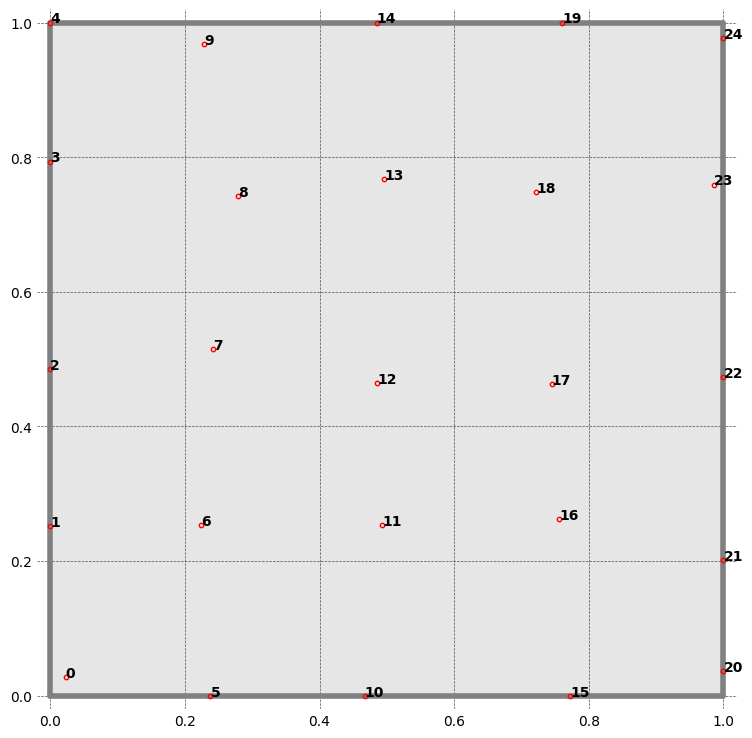

In [34]:
fig, ax = plt.subplots(1, 1, figsize=(14,7))
for i in range(NUM_OF_CUES):
    plt.annotate(text=i, xy=Env.objects['objects'][i],fontweight='bold', fontsize=10)
Env.plot_environment(gridlines=True, fig=fig, ax=ax) #visualises current environment with walls and objects
plt.show()

In [35]:
Ag = Agent(Environment=Env, params={'speed_mean':0.1})

# agent configs
# Ag.pos = start_pos
Ag.thigmotaxis = 0.2

In [36]:
MINUTES = 60

In [37]:
for i in range(int(MINUTES*60/Ag.dt)):
    Ag.update()

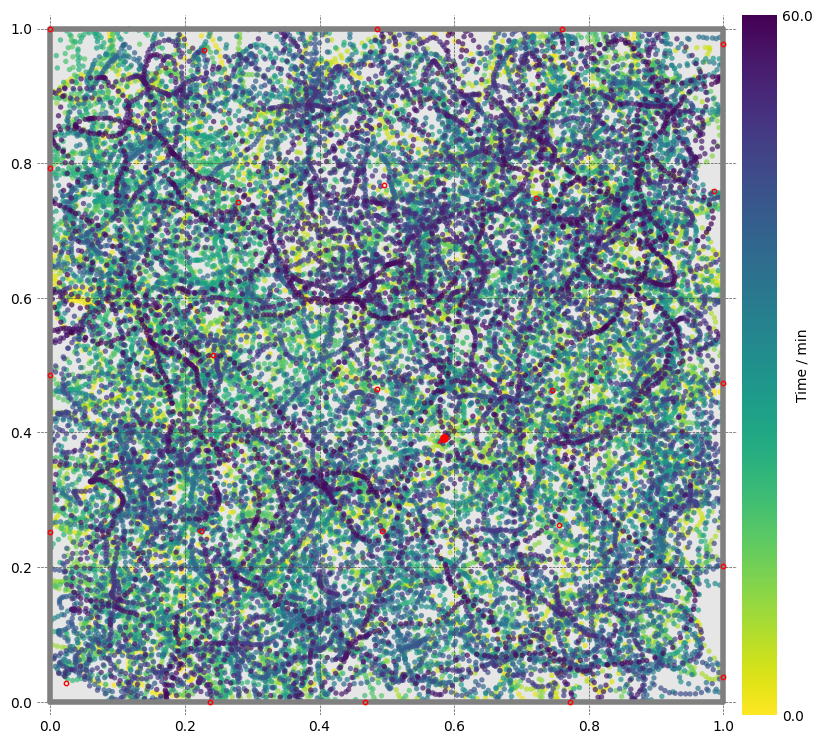

In [38]:
fig, ax = plt.subplots(1, 1, figsize=(14,7))
ax = Ag.plot_trajectory(color='changing', colorbar=True, gridlines=True,fig=fig, ax=ax)
plt.show()

# init dfbase

In [39]:
dfbase = pd.DataFrame(Ag.history).copy()
print(dfbase.shape)
dfbase.head(2)

(72000, 6)


,t,pos,distance_travelled,vel,rot_vel,head_direction
0,0.05,"[0.1081603832514918, 0.04361498596734858]",0.004493,"[0.07825502012911212, 0.04417973145600204]",4.664671,"[0.9364924050485655, 0.35068786019244197]"
1,0.10,"[0.11143745714692871, 0.046544368748283174]",0.008889,"[0.06554147790873821, 0.05858765561869192]",4.309600,"[0.8863581262995255, 0.4630002936746308]"


In [40]:
df = dfbase.copy()
df.shape

(72000, 6)

## adding obj pos and names to dfbase

In [41]:
Env.objects.keys()

dict_keys(['objects', 'object_types', 'object_names'])

In [42]:
for i in range(NUM_OF_CUES):
    cue_dict = {f'obj_{i}_pos':[Env.objects['objects'][i] for _ in df.index],
         f'obj_{i}_name':[Env.objects['object_names'][i] for _ in df.index],}
    cue_df = pd.DataFrame(data=cue_dict, index=df.index)  
    df = pd.concat([df, cue_df], axis=1)

In [43]:
# for i in range(NUM_OF_CUES):
#     cue_dict = {f'obj_{i}_pos':[Env.objects['objects'][i] for _ in ap.index],
#          f'obj_{i}_name':[Env.objects['object_names'][i] for _ in ap.index]}
#     cue_ap = pd.DataFrame(data=cue_dict, index=ap.index)  
#     ap = pd.concat([ap, cue_ap], axis=1)
#     # df[f'obj_{i}_pos'] = [Env.objects['objects'][i] for _ in df.index]
#     # df[f'obj_{i}_name'] = [Env.objects['object_names'][i] for _ in df.index]

In [44]:
# ap.head()

In [45]:
# df.shape, ap.shape

In [46]:
df.head(2)

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,obj_20_pos,obj_20_name,obj_21_pos,obj_21_name,obj_22_pos,obj_22_name,obj_23_pos,obj_23_name,obj_24_pos,obj_24_name
0,0.05,"[0.1081603832514918, 0.04361498596734858]",0.004493,"[0.07825502012911212, 0.04417973145600204]",4.664671,"[0.9364924050485655, 0.35068786019244197]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,"[1.0, 0.03661342911221448]",GFLV,"[1.0, 0.20163715696792245]",VLKJ,"[1.0, 0.47384793352524796]",TSEH,"[0.9860697712267116, 0.7593567577581513]",KDZD,"[1.0, 0.9770626899875797]",VQEX
1,0.10,"[0.11143745714692871, 0.046544368748283174]",0.008889,"[0.06554147790873821, 0.05858765561869192]",4.309600,"[0.8863581262995255, 0.4630002936746308]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,"[1.0, 0.03661342911221448]",GFLV,"[1.0, 0.20163715696792245]",VLKJ,"[1.0, 0.47384793352524796]",TSEH,"[0.9860697712267116, 0.7593567577581513]",KDZD,"[1.0, 0.9770626899875797]",VQEX


In [47]:
# ap.shape

## measure distances to objs

In [48]:
for i in range(NUM_OF_CUES):
    dist_cue_dict = {f'dist_to_obj_{i}': df.apply(apply_eucd_dist, axis=1, obj=i)}
    dist_cue_df = pd.DataFrame(data=dist_cue_dict, index=df.index)
    df = pd.concat([df, dist_cue_df], axis=1)

In [49]:
# for i in range(NUM_OF_CUES):
#     dist_cue_dict = {f'dist_to_obj_{i}': ap.apply(apply_eucd_dist, axis=1, obj=i)}
#     dist_cue_ap = pd.DataFrame(data=dist_cue_dict, index=ap.index)
#     ap = pd.concat([ap, dist_cue_ap], axis=1)

In [50]:
# ap.head()

In [51]:
# df.columns

In [52]:
# df[[feat for feat in df.columns if feat.startswith('dist_')]].mean()

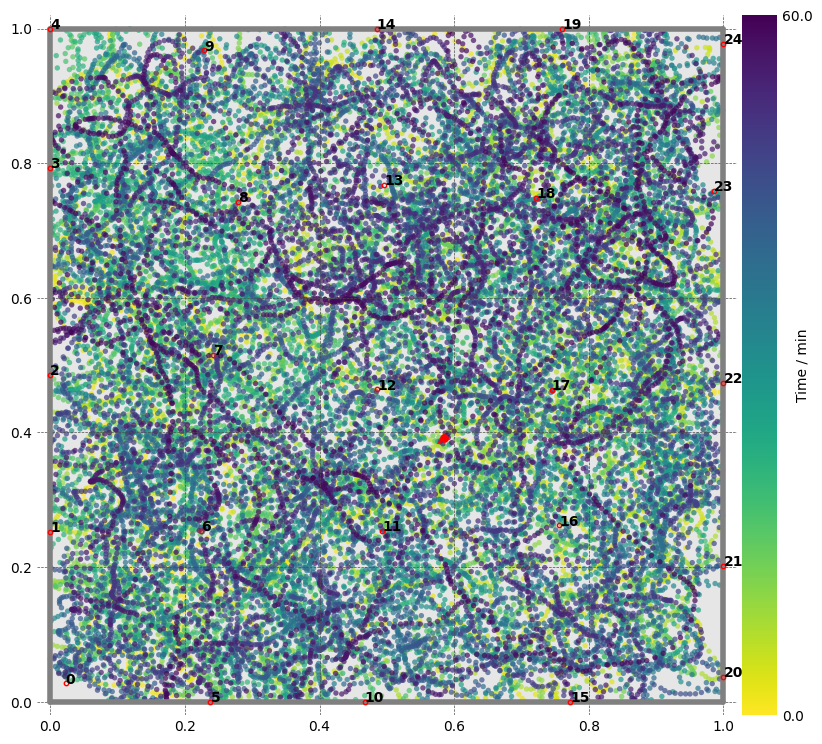

In [53]:
fig, ax = plt.subplots(1, 1, figsize=(14,7))
for i in range(NUM_OF_CUES):
    plt.annotate(text=i, xy=Env.objects['objects'][i], fontsize=10, fontweight='bold')
ax = Ag.plot_trajectory(color='changing', colorbar=True, gridlines=True,fig=fig, ax=ax, t_start=0, t_end=df['t'].max())

plt.show()

In [54]:
obj_names = [Env.objects['object_names'][i] for i in range(NUM_OF_CUES)]
obj_dist_cols = [f'dist_to_obj_{i}' for i in range(NUM_OF_CUES)]

# def get_position_text(x):

In [55]:
apd['obj_0_pos'].values[0]

array([0.02256549, 0.02753175])

In [130]:
np.round(df['pos'].values[0], 3)

array([0.108, 0.044])

In [131]:
df['pos'] = [np.round(val, 3) for val in df['pos']]

In [132]:
df.head()

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,dist_to_obj_15,dist_to_obj_16,dist_to_obj_17,dist_to_obj_18,dist_to_obj_19,dist_to_obj_20,dist_to_obj_21,dist_to_obj_22,dist_to_obj_23,dist_to_obj_24
0,0.05,"[0.108, 0.044]",0.004493,"[0.07825502012911212, 0.04417973145600204]",4.664671,"[0.9364924050485655, 0.35068786019244197]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.666038,0.683608,0.762393,0.934964,1.157688,0.891867,0.905731,0.990191,1.132701,1.291008
1,0.10,"[0.111, 0.047]",0.008889,"[0.06554147790873821, 0.05858765561869192]",4.309600,"[0.8863581262995255, 0.4630002936746308]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.662967,0.679569,0.758045,0.930603,1.153422,0.888618,0.901996,0.985967,1.128310,1.286626
2,0.15,"[0.116, 0.05]",0.015121,"[0.09702576630862492, 0.07825506978033414]",-1.014355,"[0.8540567915661367, 0.5201797735204211]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.658416,0.673731,0.751842,0.924468,1.147459,0.883820,0.896549,0.979901,1.122077,1.280447
3,0.20,"[0.121, 0.055]",0.021547,"[0.09525515697705184, 0.08628144176523148]",1.145814,"[0.819671186672009, 0.5728343091502993]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.654014,0.667859,0.745493,0.918088,1.141216,0.879136,0.891134,0.973743,1.115660,1.274038
4,0.25,"[0.126, 0.06]",0.028791,"[0.09036555082254455, 0.113222275875514]",3.223861,"[0.7613447368657118, 0.6483472770413092]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.650014,0.661819,0.738615,0.910851,1.133995,0.874755,0.885758,0.967234,1.108583,1.266823


## create positions

In [133]:
def apply_cps_to_positions(df, obj_dist_cols):
    dft = df[obj_dist_cols].T
    dft.columns = [f't_{i:08d}' for i in range(df.T.shape[1])]
    # order = [int(val.split('_')[-1]) for val in dft.sort_values(dft.columns[0]).index[:MAX_NUMBER_OF_CUES]]
    # dft.sort_values(dft.columns[0])

    positions_list = []
    mean_dist = []
    position_enc_list = []
    for feat in dft.columns:
        order = [int(val.split('_')[-1]) for val in dft.sort_values(feat).index[:MAX_NUMBER_OF_CUES]]
        dists = [val for val in dft.sort_values(feat)[feat][:MAX_NUMBER_OF_CUES]]
        mean_dist.append(np.mean(dists))
        positions_list.append(''.join([obj_names[i] for i in order]))
        # position_enc_list.append(np.hstack([objects_encode_list[i] for i in order]))

    # len(positions_list)


    pos_state_info_dict = {'position_state':[val for val in positions_list],
                           'mean_distance':[val for val in mean_dist]}
    pos_state_df = pd.DataFrame(data=pos_state_info_dict, index=df.index)
    return pd.concat([df, pos_state_df], axis=1).copy()

In [58]:
# ap.head()

In [59]:
# ap.shape

In [60]:
# df[obj_dist_cols].T

In [134]:
def apply_cps_to_positions_new(df, obj_dist_cols):
    """
    Para cada linha de df, ordena os objetos em obj_dist_cols
    pela distância até df['pos'], pega os MAX_NUMBER_OF_CUES
    mais próximos, e retorna position_state e mean_distance
    exatamente como sua versão original.
    
    Inputs:
    - df             : pd.DataFrame, com colunas 'pos' e obj_dist_cols
                       em que cada df[col] é um list-like [x,y].
    - obj_dist_cols  : List[str], nomes das colunas de objeto ex. ['obj_0_pos', ...]
    
    REQUER que existam no escopo global:
      MAX_NUMBER_OF_CUES : int
      obj_names          : List[str] de mesmo tamanho que obj_dist_cols
    """
    # 1) extrai array de posições do agente: shape (N, 2)
    pos_arr = np.vstack(df['pos'].values)  # cada entry é [x,y]
    
    # 2) empilha todas as posições de objetos: shape (N, M, 2)
    obj_pos_arr = np.stack([
        np.vstack(df[col].values) for col in obj_dist_cols
    ], axis=1)
    
    # 3) calcula distâncias euclidianas vetorizadas: shape (N, M)
    dists = np.linalg.norm(obj_pos_arr - pos_arr[:, None, :], axis=2)
    
    # 4) monta DataFrame de distâncias, para transpor como antes
    dist_df = pd.DataFrame(dists, columns=obj_dist_cols, index=df.index)
    dft = dist_df.T
    # renomeia colunas para 't_00000000' ... (igual à sua versão)
    dft.columns = [f't_{i:08d}' for i in range(df.shape[0])]

    # --- agora mantém o seu loop original ---
    positions_list = []
    mean_dist = []
    for feat in dft.columns:
        # pega os índices dos MAX_NUMBER_OF_CUES menores distâncias
        order = [
            int(val.split('_')[-1])
            for val in dft.sort_values(feat).index[:MAX_NUMBER_OF_CUES]
        ]
        # extrai as distâncias e faz a média
        dvals = dft.sort_values(feat)[feat][:MAX_NUMBER_OF_CUES].values
        mean_dist.append(dvals.mean())
        # concatena nomes
        positions_list.append(''.join(obj_names[i] for i in order))

    # monta o DataFrame de saída
    pos_state_info_dict = {
        'position_state': positions_list,
        'mean_distance': mean_dist
    }
    pos_state_df = pd.DataFrame(pos_state_info_dict, index=df.index)

    return pd.concat([df, pos_state_df], axis=1).copy()

In [135]:
# apd = apply_cps_to_positions_new(ap, obj_dist_cols)

In [136]:
# ap.columns

In [137]:
dfp = apply_cps_to_positions(df, obj_dist_cols)
dfp.shape

(72000, 83)

In [75]:
# ap.iloc[0:100_000].shape

In [76]:
# apd_2 = apply_cps_to_positions(ap.iloc[100_000:200_000], obj_dist_cols)

In [77]:
# for i in range(2, 11):
#     apd_2 = apply_cps_to_positions(ap.iloc[(i-1)*100_000:i*100_000], obj_dist_cols)
#     print(f"{(i-1)*100_000}:{i*100_000} pronto")
#     apd_2.to_parquet(f'apd{i}.gzip')

In [78]:
# ap.iloc[1_000_000:]

In [79]:
# apd = apply_cps_to_positions(ap.iloc[1_000_000:], obj_dist_cols)
# apd.shape

In [80]:
# apd.to_parquet(f'apd11.gzip')

## apd loop

In [ ]:
# apd_list = [pd.read_parquet(f'apd{i}.gzip') for i in range(1, 12)]


# # apd_full = pd.concat(apd_list, ignore_index=True)
# # apd_full.shape

In [52]:
# for i in range(2, 12):
#     print(f'apd{i}.gzip')

In [53]:
# apd_full = pd.concat(apd_list,)

In [54]:
# apd_full.shape

In [138]:
len(dfp), dfp['position_state'].nunique()/len(dfp), dfp['position_state'].nunique()

(72000, 0.013277777777777777, 956)

In [139]:
len(apd), apd['position_state'].nunique()/len(apd), apd['position_state'].nunique()

(1002001, 0.0010548891667772787, 1057)

In [140]:
apd.head()

,X,Y,pos,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,obj_2_pos,obj_2_name,obj_3_pos,...,dist_to_obj_19,dist_to_obj_20,dist_to_obj_21,dist_to_obj_22,dist_to_obj_23,dist_to_obj_24,position_state,mean_distance,position_state_id,normalized_position_state_id
0,0.000,0.0,"[0.0, 0.0]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,1.256338,1.000670,1.020126,1.106586,1.244571,1.398089,COQVSOAUMTASMTUPCRFN,0.266292,256,0.267782
1,0.001,0.0,"[0.001, 0.0]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,1.255733,0.999671,1.019146,1.105682,1.243779,1.397373,COQVSOAUMTASMTUPCRFN,0.265635,256,0.267782
2,0.002,0.0,"[0.002, 0.0]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,1.255128,0.998671,1.018166,1.104779,1.242987,1.396659,COQVSOAUMTASMTUPCRFN,0.264982,256,0.267782
3,0.003,0.0,"[0.003, 0.0]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,1.254524,0.997672,1.017186,1.103875,1.242195,1.395944,COQVSOAUMTASMTUPCRFN,0.264335,256,0.267782
4,0.004,0.0,"[0.004, 0.0]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,1.253921,0.996673,1.016205,1.102972,1.241404,1.395230,COQVSOAUMTASMTUPCRFN,0.263692,256,0.267782


In [141]:
dfp.head()

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,dist_to_obj_17,dist_to_obj_18,dist_to_obj_19,dist_to_obj_20,dist_to_obj_21,dist_to_obj_22,dist_to_obj_23,dist_to_obj_24,position_state,mean_distance
0,0.05,"[0.108, 0.044]",0.004493,"[0.07825502012911212, 0.04417973145600204]",4.664671,"[0.9364924050485655, 0.35068786019244197]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.762393,0.934964,1.157688,0.891867,0.905731,0.990191,1.132701,1.291008,COQVSOAUMTASMTUPCRFN,0.212105
1,0.10,"[0.111, 0.047]",0.008889,"[0.06554147790873821, 0.05858765561869192]",4.309600,"[0.8863581262995255, 0.4630002936746308]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.758045,0.930603,1.153422,0.888618,0.901996,0.985967,1.128310,1.286626,COQVSOAUMTASMTUPCRFN,0.210823
2,0.15,"[0.116, 0.05]",0.015121,"[0.09702576630862492, 0.07825506978033414]",-1.014355,"[0.8540567915661367, 0.5201797735204211]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.751842,0.924468,1.147459,0.883820,0.896549,0.979901,1.122077,1.280447,COQVSOAUMTUPMTASCRFN,0.209112
3,0.20,"[0.121, 0.055]",0.021547,"[0.09525515697705184, 0.08628144176523148]",1.145814,"[0.819671186672009, 0.5728343091502993]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.745493,0.918088,1.141216,0.879136,0.891134,0.973743,1.115660,1.274038,COQVSOAUMTUPMTASCRFN,0.207453
4,0.25,"[0.126, 0.06]",0.028791,"[0.09036555082254455, 0.113222275875514]",3.223861,"[0.7613447368657118, 0.6483472770413092]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.738615,0.910851,1.133995,0.874755,0.885758,0.967234,1.108583,1.266823,COQVSOAUMTUPMTASCRFN,0.205747


In [142]:
num_unique_pos = dfp['position_state'].nunique()
num_unique_pos

956

In [143]:
apd['position_state_id'] = (apd.groupby('position_state').transform('ngroup'))
apd['normalized_position_state_id']  = (apd['position_state_id'] / num_unique_pos)
apd[['position_state', 'position_state_id', 'normalized_position_state_id']].sample(5)

,position_state,position_state_id,normalized_position_state_id
25771,TKVXYGWPGFLVCRFNVLKJ,823,0.860879
51940,GFLVTKVXVLKJYGWPCRFN,356,0.372385
802098,CEPVXSOPMOWWNFTUDCTA,236,0.246862
306602,MTUPIGAMDCTACCOOMTAS,610,0.638075
690334,AOWPMOWWPIPZCCOOXYCO,35,0.036611


In [145]:
full_to_sample_position_state_to_id = {ps:idx for ps, idx in zip(apd['position_state'], apd['position_state_id'])}

In [146]:
apd[['X', 'Y','position_state_id', 'position_state']].sample(5)

,X,Y,position_state_id,position_state
41041,0.000,0.041,252,COQVMTASSOAUMTUPHOBB
982903,0.922,0.981,930,VQEXXYCOKDZDAOWPNFTU
525147,0.623,0.524,733,PIPZCCOOAOWPMOWWYGWP
437677,0.240,0.437,352,DCTAMTUPHOBBCCOOMTAS
559025,0.467,0.558,140,CCOOMOWWDCTACEPVPIPZ


In [156]:
count=0
for pos, ps in zip(dfp['pos'], dfp['position_state']):
    if ps not in full_to_sample_position_state_to_id:
        print(apd[(apd['X'] == pos[0])&(apd['Y'] == pos[1])][['pos','position_state', 'position_state_id']], pos)
        apd_id = apd[(apd['X'] == pos[0])&(apd['Y'] == pos[1])]['position_state_id'].values[0]
        print(ps)
        count+=1
        full_to_sample_position_state_to_id[ps] = apd_id


                  pos        position_state  position_state_id
355975  [0.62, 0.355]  IGAMYGWPPIPZCCOOCRFN                464 [0.62  0.355]
IGAMPIPZYGWPCCOOTKVX
                   pos        position_state  position_state_id
747134  [0.388, 0.746]  CEPVMOWWNFTUXSOPDCTA                216 [0.388 0.746]
CEPVMOWWNFTUDCTAXSOP


In [148]:
dfp[dfp['position_state'] == 'IGAMPIPZYGWPCCOOTKVX']

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,dist_to_obj_17,dist_to_obj_18,dist_to_obj_19,dist_to_obj_20,dist_to_obj_21,dist_to_obj_22,dist_to_obj_23,dist_to_obj_24,position_state,mean_distance
19038,951.95,"[0.62, 0.355]",114.271196,"[0.056021305720475034, -0.11901604132866894]",-1.257854,"[0.37034274429495107, -0.9288951780196109]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.164658,0.406184,0.659643,0.495878,0.409751,0.397813,0.544968,0.72845,IGAMPIPZYGWPCCOOTKVX,0.210361


In [149]:
dfp[dfp['position_state'] == 'CEPVMOWWNFTUDCTAXSOP']

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,dist_to_obj_17,dist_to_obj_18,dist_to_obj_19,dist_to_obj_20,dist_to_obj_21,dist_to_obj_22,dist_to_obj_23,dist_to_obj_24,position_state,mean_distance
68629,3431.5,"[0.388, 0.746]",413.316068,"[-0.008219154591461164, 0.04072081653543558]",2.062624,"[-0.12953808588816088, 0.9915744471820718]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.454897,0.334348,0.451145,0.936606,0.818823,0.669654,0.598273,0.654357,CEPVMOWWNFTUDCTAXSOP,0.207591


In [150]:
apd[apd['position_state'].str.startswith('CEPVMOWWNFTU')]

,X,Y,pos,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,obj_2_pos,obj_2_name,obj_3_pos,...,dist_to_obj_19,dist_to_obj_20,dist_to_obj_21,dist_to_obj_22,dist_to_obj_23,dist_to_obj_24,position_state,mean_distance,position_state_id,normalized_position_state_id
747133,0.387,0.746,"[0.387, 0.746]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,0.451697,0.937549,0.819817,0.670698,0.599219,0.655102,CEPVMOWWNFTUXSOPDCTA,0.207352,216,0.225941
747134,0.388,0.746,"[0.388, 0.746]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,0.450871,0.936896,0.819070,0.669784,0.598219,0.654167,CEPVMOWWNFTUXSOPDCTA,0.207508,216,0.225941
748134,0.387,0.747,"[0.387, 0.747]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,0.451136,0.938306,0.820481,0.671104,0.599197,0.654750,CEPVMOWWNFTUXSOPDCTA,0.207141,216,0.225941
748135,0.388,0.747,"[0.388, 0.747]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,0.450308,0.937653,0.819734,0.670191,0.598197,0.653814,CEPVMOWWNFTUXSOPDCTA,0.207297,216,0.225941
749135,0.387,0.748,"[0.387, 0.748]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,0.450576,0.939063,0.821146,0.671512,0.599177,0.654400,CEPVMOWWNFTUXSOPDCTA,0.206935,216,0.225941
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
878250,0.373,0.877,"[0.373, 0.877]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,0.406569,1.048513,0.921544,0.745426,0.624255,0.634934,CEPVMOWWNFTUXSOPAOWP,0.207542,215,0.224895
879248,0.370,0.878,"[0.37, 0.878]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,0.409130,1.051110,0.924320,0.748491,0.627390,0.637741,CEPVMOWWNFTUXSOPAOWP,0.208230,215,0.224895
879249,0.371,0.878,"[0.371, 0.878]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,0.408175,1.050511,0.923638,0.747650,0.626408,0.636753,CEPVMOWWNFTUXSOPAOWP,0.208036,215,0.224895
879250,0.372,0.878,"[0.372, 0.878]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,0.407221,1.049912,0.922958,0.746808,0.625426,0.635765,CEPVMOWWNFTUXSOPAOWP,0.207845,215,0.224895


In [115]:
count

2

In [157]:
dfp['position_state_id'] = [full_to_sample_position_state_to_id[ps] for ps in dfp['position_state']]
dfp['normalized_position_state_id']  = (dfp['position_state_id'] / num_unique_pos)
dfp[['position_state_id', 'normalized_position_state_id']].sample(5)

,position_state_id,normalized_position_state_id
29484,622,0.650628
56910,387,0.404812
31197,199,0.208159
71394,1022,1.069038
31691,868,0.907950


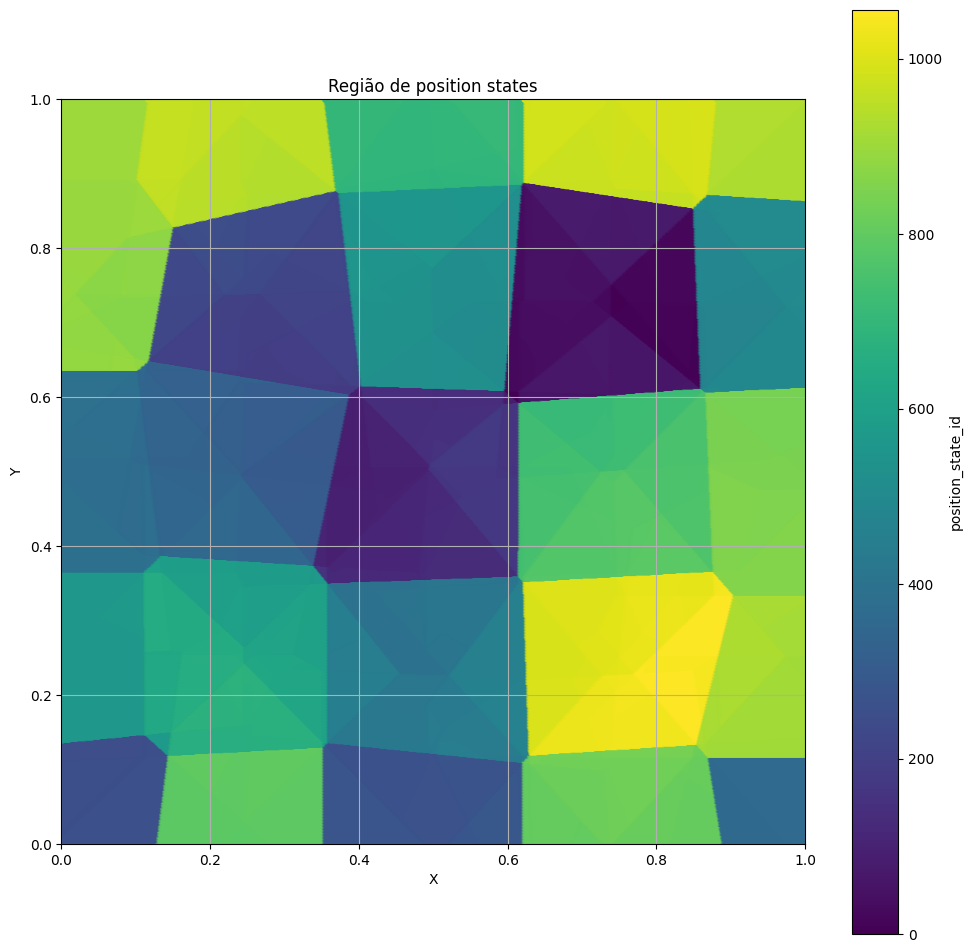

In [158]:
plt.figure(figsize=(12, 12))
scatter = plt.scatter(apd['X'], apd['Y'], c=apd['position_state_id'], cmap='viridis', s=15)
# Adiciona barra de cores
cbar = plt.colorbar(scatter)
cbar.set_label('position_state_id')

# Configurações visuais
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Região de position states')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True)
plt.gca().set_aspect('equal', adjustable='box')  # ambiente 1x1

plt.show()

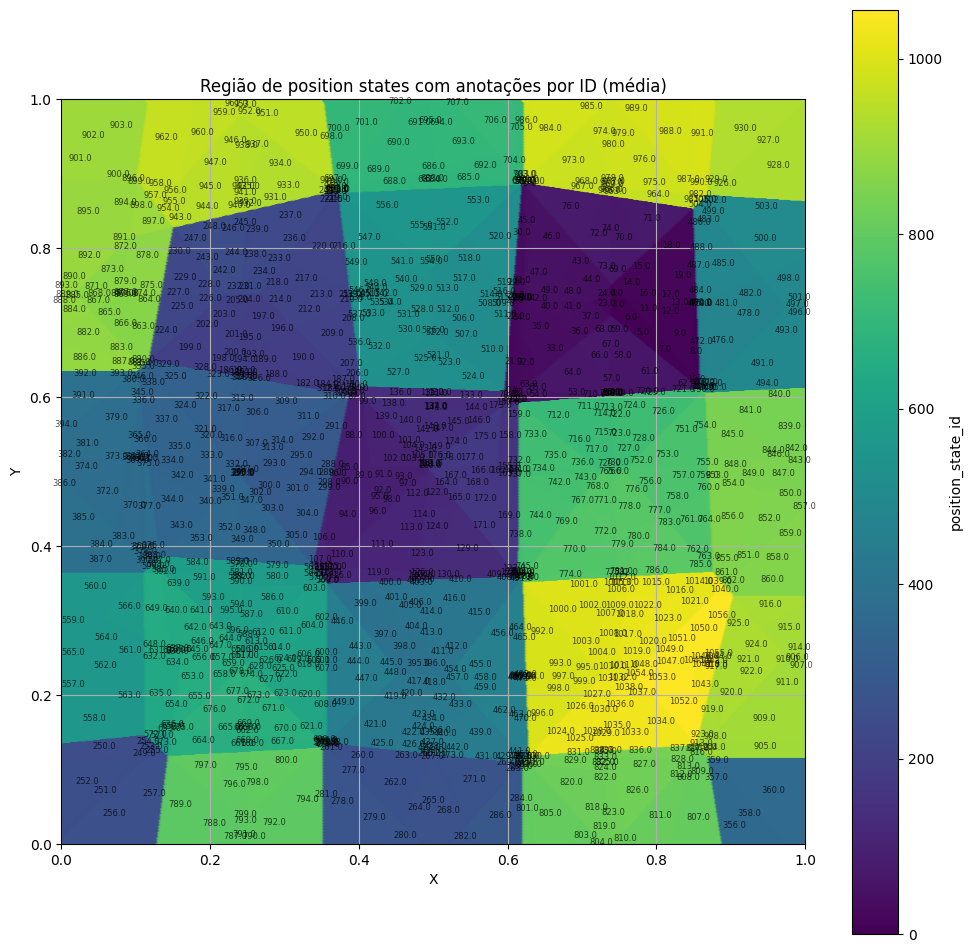

In [159]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 12))

# Scatter plot com cor por position_state_id
scatter = plt.scatter(apd['X'], apd['Y'], c=apd['position_state_id'], cmap='viridis', s=15)

# Adiciona barra de cores
cbar = plt.colorbar(scatter)
cbar.set_label('position_state_id')

# Agrupa por position_state_id e calcula média de X e Y
group_means = apd.groupby('position_state_id')[['X', 'Y']].mean().reset_index()

# Anota cada ponto médio com o ID
for _, row in group_means.iterrows():
    plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                 fontsize=6, alpha=0.7, ha='center', va='center')

# Configurações visuais
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Região de position states com anotações por ID (média)')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(True)
plt.gca().set_aspect('equal', adjustable='box')

plt.show()


In [74]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_position_states(apd, grupos_destacados):
    """
    Plota os pontos do DataFrame apd (com colunas X, Y e position_state_id),
    destacando apenas os grupos na lista grupos_destacados, com anotações.

    Parâmetros:
    - apd: DataFrame com colunas 'X', 'Y' e 'position_state_id'
    - grupos_destacados: lista de valores de position_state_id a serem coloridos e anotados
    """
    # Criação da máscara de seleção
    destaque_mask = apd['position_state_id'].isin(grupos_destacados)

    # Define cores: branco ou cinza claro para os pontos não destacados
    cor_base = '#e0e0e0'
    
    plt.figure(figsize=(12, 12))

    # Plota todos os pontos em cinza claro
    plt.scatter(apd['X'], apd['Y'], color=cor_base, s=10, label='Outros')

    # Plota apenas os pontos destacados com colormap
    destacados = apd[destaque_mask]
    if not destacados.empty:
        scatter = plt.scatter(destacados['X'], destacados['Y'],
                              c=destacados['position_state_id'], cmap='tab10', s=25, label='Destacados')

        # Anotar a média dos grupos destacados
        medias = destacados.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
        for _, row in medias.iterrows():
            plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
                         fontsize=7, alpha=0.9, ha='center', va='center', fontweight='bold')

        # Adiciona colorbar apenas se houver grupos destacados
        cbar = plt.colorbar(scatter)
        cbar.set_label('position_state_id destacado')

    # Layout
    plt.xlabel('X')
    plt.ylabel('Y')
    plt.title('Grupos destacados por position_state_id')
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.legend()
    plt.show()


In [160]:
apd['position_state_id'].nunique()

1057

In [161]:
apd.groupby('position_state_id').size().describe()

count    1057.000000
mean      947.966887
std      1310.025227
min         1.000000
25%        66.000000
50%       385.000000
75%      1319.000000
max      9124.000000
dtype: float64

In [162]:
apd['position_state_id'].value_counts()

position_state_id
360    9124
256    7707
930    7182
895    6928
928    6922
       ... 
917       1
679       1
259       1
51        1
740       1
Name: count, Length: 1057, dtype: int64

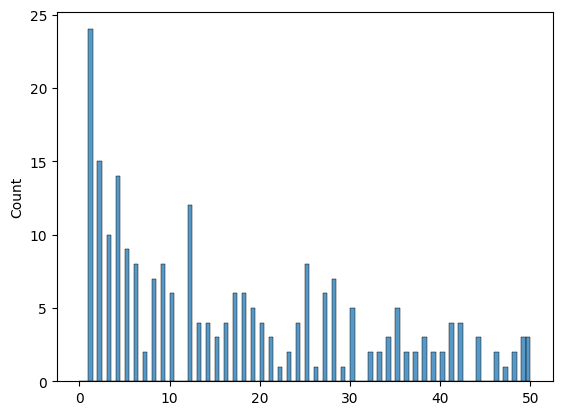

In [163]:
import seaborn as sns
sns.histplot(apd.groupby('position_state_id').size(), binwidth=0.5, binrange=(0, 50))
plt.show()

/home/mgteus/workspace/navitrans/.nav/lib/python3.8/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


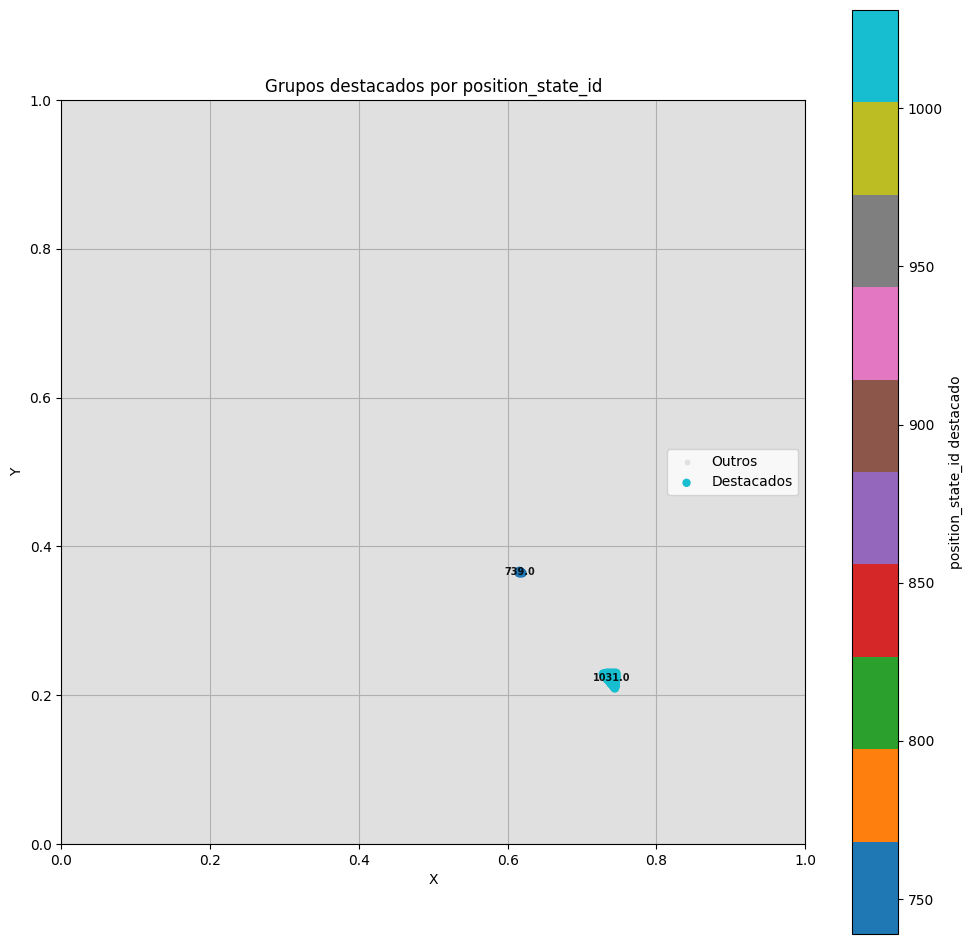

In [164]:
grupos_para_destacar = [1031, 739]
plot_position_states(apd, grupos_para_destacar)

In [81]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

def plot_position_states_imshow(apd, resolucao=100):
    """
    Plota o mapa completo de position_state_id usando imshow.
    Cada grupo é pintado com uma cor única.
    Um rótulo com o ID é anotado na posição média de cada grupo.

    Parâmetros:
    - apd: DataFrame com colunas X, Y, position_state_id
    - resolucao: tamanho da grade (resolucao x resolucao)
    """
    # Converte X, Y para coordenadas discretas da grade
    xs = (apd['X'] * (resolucao - 1)).astype(int)
    ys = ((1 - apd['Y']) * (resolucao - 1)).astype(int)  # inverte Y para alinhar com o eixo da imagem

    # Inicializa grade com valor inválido (-1)
    mapa = np.full((resolucao, resolucao), -1, dtype=int)

    # Preenche a grade com os position_state_id
    for x, y, pid in zip(xs, ys, apd['position_state_id']):
        mapa[y, x] = pid  # y = linha, x = coluna

    # IDs únicos válidos (exclui -1)
    unique_ids = np.unique(mapa)
    unique_ids = unique_ids[unique_ids >= 0]

    # Mapear IDs para índices de cor
    id_to_idx = {pid: idx for idx, pid in enumerate(unique_ids)}
    color_mapa = np.zeros_like(mapa)
    for pid, idx in id_to_idx.items():
        color_mapa[mapa == pid] = idx

    # Cria colormap discreto
    cmap = plt.cm.get_cmap('tab20', len(unique_ids))
    norm = mcolors.BoundaryNorm(boundaries=np.arange(-0.5, len(unique_ids) + 0.5), ncolors=cmap.N)

    # Plot da imagem
    plt.figure(figsize=(15, 15))
    plt.imshow(color_mapa, cmap=cmap, norm=norm, origin='upper', extent=[0, 1, 0, 1], interpolation='none')

    # Anotar ponto médio de cada grupo
    medias = apd.groupby('position_state_id')[['X', 'Y']].mean().reset_index()
    # for _, row in medias.iterrows():
    #     plt.annotate(str(row['position_state_id']), (row['X'], row['Y']),
    #                  fontsize=7, color='black', ha='center', va='center', fontweight='bold', alpha=0.8)

    # Layout
    plt.title("Mapa completo de position_state_id com anotações")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(False)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.show()


In [82]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import networkx as nx

def plot_position_states_imshow_graph(apd, resolucao=100):
    """
    Plota o mapa completo de position_state_id usando imshow com coloração inteligente:
    grupos vizinhos recebem cores diferentes.

    Parâmetros:
    - apd: DataFrame com colunas X, Y, position_state_id
    - resolucao: tamanho da grade (resolucao x resolucao)
    """
    # Converte X, Y para coordenadas discretas da grade
    xs = (apd['X'] * (resolucao - 1)).astype(int)
    ys = ((1 - apd['Y']) * (resolucao - 1)).astype(int)

    # Inicializa grade com valor inválido (-1)
    mapa = np.full((resolucao, resolucao), -1, dtype=int)

    for x, y, pid in zip(xs, ys, apd['position_state_id']):
        mapa[y, x] = pid  # y = linha, x = coluna

    # IDs únicos válidos (exclui -1)
    unique_ids = np.unique(mapa)
    unique_ids = unique_ids[unique_ids >= 0]

    # --- Construção do grafo de vizinhança ---
    G = nx.Graph()
    for i in range(resolucao - 1):
        for j in range(resolucao - 1):
            pid = mapa[i, j]
            if pid == -1:
                continue
            for di, dj in [(0, 1), (1, 0)]:
                ni, nj = i + di, j + dj
                if 0 <= ni < resolucao and 0 <= nj < resolucao:
                    vizinho = mapa[ni, nj]
                    if vizinho != -1 and vizinho != pid:
                        G.add_edge(pid, vizinho)

    # --- Colorização do grafo ---
    color_map = nx.coloring.greedy_color(G, strategy='largest_first')
    max_color = max(color_map.values()) + 1

    # Mapeia position_state_id para índices de cor
    pid_to_color_idx = {pid: color_map.get(pid, 0) for pid in unique_ids}

    # Preenche o mapa de cores
    color_mapa = np.zeros_like(mapa, dtype=int)
    for pid in unique_ids:
        idx = pid_to_color_idx[pid]
        color_mapa[mapa == pid] = idx

    # Colormap e normalização
    cmap = plt.cm.get_cmap('tab20', max_color)
    norm = mcolors.BoundaryNorm(boundaries=np.arange(-0.5, max_color + 0.5), ncolors=cmap.N)

    # --- Plot ---
    plt.figure(figsize=(15, 15))
    plt.imshow(color_mapa, cmap=cmap, norm=norm, origin='upper',
               extent=[0, 1, 0, 1], interpolation='none')

    # Layout
    plt.title("Mapa com coloração inteligente (grupos vizinhos com cores distintas)")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(False)
    plt.gca().set_aspect('equal', adjustable='box')
    plt.show()


In [97]:
# grupos_para_destacar = [2887, 1469, 1077]
# plot_position_states_imshow(apd,grupos_para_destacar)


/tmp/ipykernel_1145/1607293999.py:37: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab20', len(unique_ids))


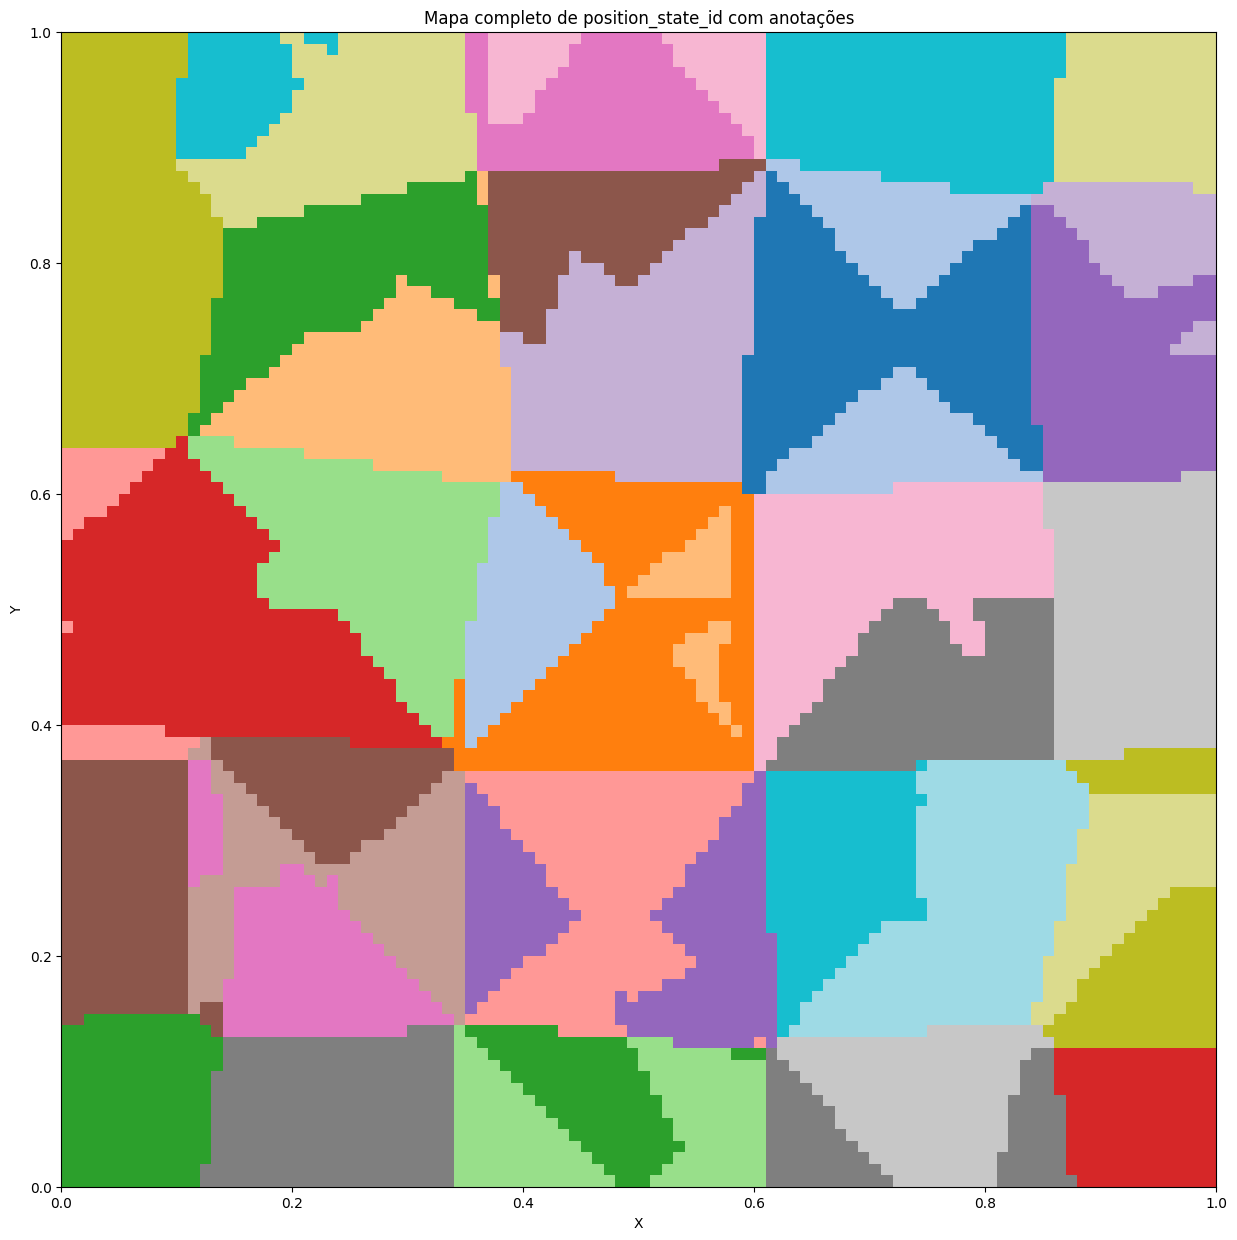

In [83]:
plot_position_states_imshow(apd)

/tmp/ipykernel_1145/1441942947.py:57: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab20', max_color)


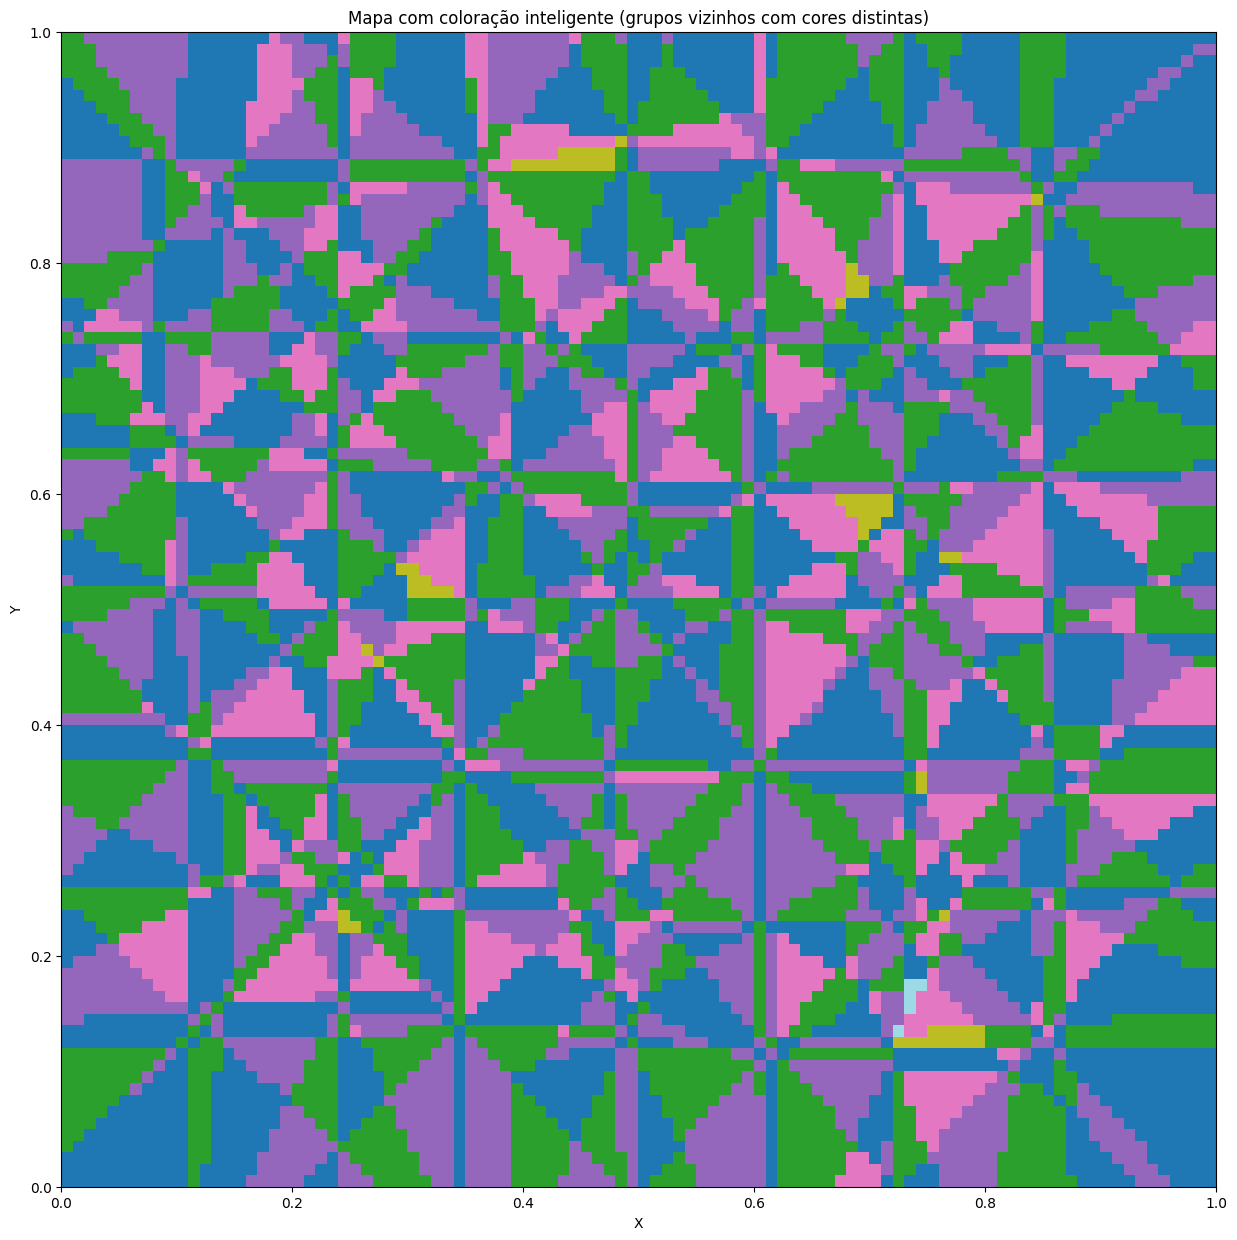

In [84]:
plot_position_states_imshow_graph(apd,)

/home/mgteus/workspace/navitrans/.nav/lib/python3.8/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


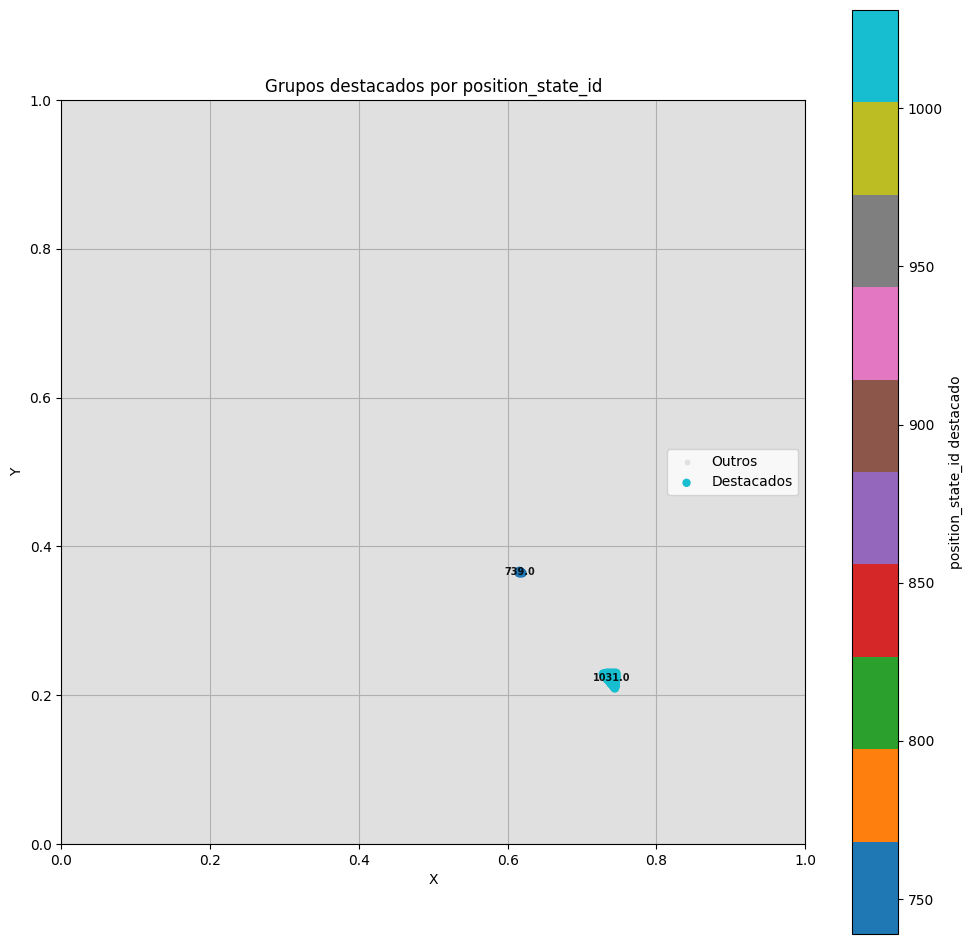

In [85]:
grupos_para_destacar = [1031, 739]
plot_position_states(apd, grupos_para_destacar)

In [86]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import networkx as nx

def plot_position_states_with_objects(apd, Env, resolucao=100):
    """
    Plota o mapa de position_state_id com coloração inteligente para vizinhos
    e insere pontos de objetos sobrepostos via scatter (em preto).

    Parâmetros:
    - apd: DataFrame com colunas X, Y, position_state_id
    - Env: objeto com atributo Env.objects['objects'] (array Nx2 de coordenadas em [0,1])
    - resolucao: resolução da grade (resolucao x resolucao)
    """
    # Converte X, Y para coordenadas da grade
    xs = (apd['X'] * (resolucao - 1)).astype(int)
    ys = ((1 - apd['Y']) * (resolucao - 1)).astype(int)

    # Inicializa grade
    mapa = np.full((resolucao, resolucao), -1, dtype=int)
    for x, y, pid in zip(xs, ys, apd['position_state_id']):
        mapa[y, x] = pid

    # IDs válidos
    unique_ids = np.unique(mapa)
    unique_ids = unique_ids[unique_ids >= 0]

    # Grafo de vizinhança
    G = nx.Graph()
    for i in range(resolucao - 1):
        for j in range(resolucao - 1):
            pid = mapa[i, j]
            if pid == -1:
                continue
            for di, dj in [(0, 1), (1, 0)]:
                ni, nj = i + di, j + dj
                if 0 <= ni < resolucao and 0 <= nj < resolucao:
                    vizinho = mapa[ni, nj]
                    if vizinho != -1 and vizinho != pid:
                        G.add_edge(pid, vizinho)

    # Colorir com greedy coloring
    color_map = nx.coloring.greedy_color(G, strategy='largest_first')
    max_color = max(color_map.values()) + 1
    pid_to_color_idx = {pid: color_map.get(pid, 0) for pid in unique_ids}

    # Construir mapa de cores
    color_mapa = np.zeros_like(mapa, dtype=int)
    for pid in unique_ids:
        color_mapa[mapa == pid] = pid_to_color_idx[pid]

    # Colormap e normalização
    cmap = plt.cm.get_cmap('tab20', max_color)
    norm = mcolors.BoundaryNorm(boundaries=np.arange(-0.5, max_color + 0.5), ncolors=cmap.N)

    # --- Plot ---
    plt.figure(figsize=(15, 15))
    plt.imshow(color_mapa, cmap=cmap, norm=norm, origin='upper',
               extent=[0, 1, 0, 1], interpolation='none')

    # Scatter de objetos
    objetos = Env.objects['objects']
    plt.scatter(objetos[:, 0], objetos[:, 1], color='black', s=40, label='Objetos')
    for i in range(len(objetos)):
        plt.annotate(Env.objects['object_names'][i], objetos[i], fontsize=15)

    # Layout
    plt.title("Mapa de position_state_id com objetos sobrepostos")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(False)
    plt.legend()
    plt.gca().set_aspect('equal', adjustable='box')
    plt.show()


In [87]:
# Env.objects['object_names']

/tmp/ipykernel_1145/4007613002.py:54: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab20', max_color)


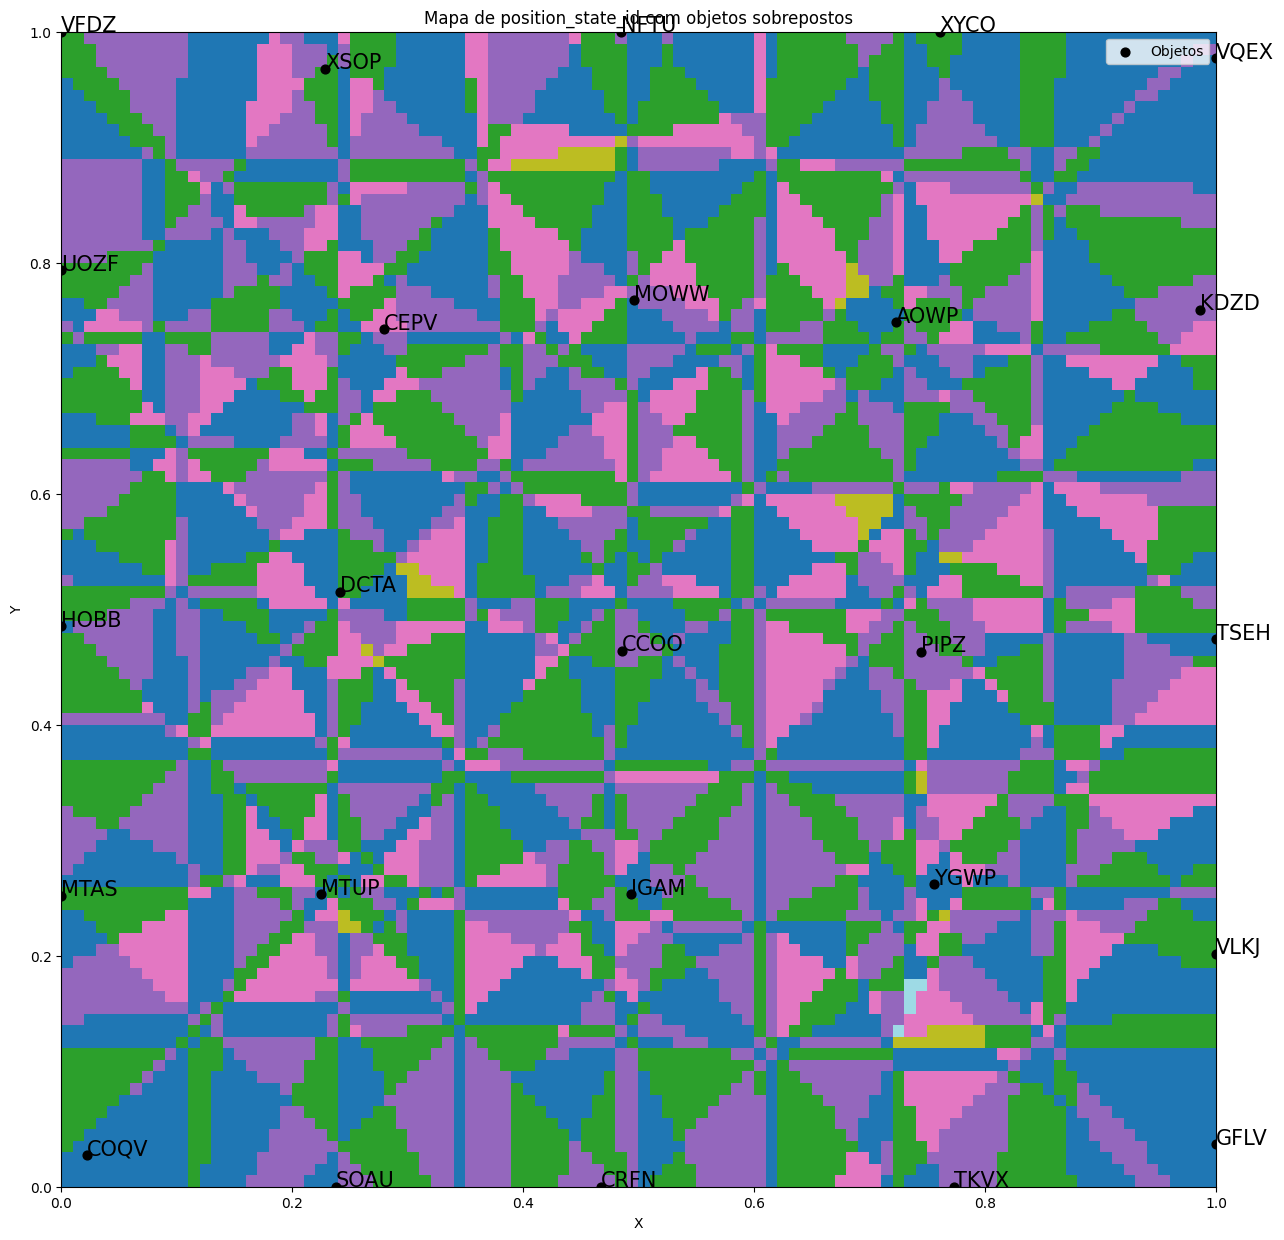

In [88]:
plot_position_states_with_objects(apd, Env)

In [106]:
apd.head()

,X,Y,pos,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,obj_2_pos,obj_2_name,obj_3_pos,...,dist_to_obj_19,dist_to_obj_20,dist_to_obj_21,dist_to_obj_22,dist_to_obj_23,dist_to_obj_24,position_state,mean_distance,position_state_id,normalized_position_state_id
0,0.000,0.0,"[0.0, 0.0]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,1.256338,1.000670,1.020126,1.106586,1.244571,1.398089,COQVSOAUMTASMTUPCRFN,0.266292,256,0.272051
1,0.001,0.0,"[0.001, 0.0]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,1.255733,0.999671,1.019146,1.105682,1.243779,1.397373,COQVSOAUMTASMTUPCRFN,0.265635,256,0.272051
2,0.002,0.0,"[0.002, 0.0]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,1.255128,0.998671,1.018166,1.104779,1.242987,1.396659,COQVSOAUMTASMTUPCRFN,0.264982,256,0.272051
3,0.003,0.0,"[0.003, 0.0]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,1.254524,0.997672,1.017186,1.103875,1.242195,1.395944,COQVSOAUMTASMTUPCRFN,0.264335,256,0.272051
4,0.004,0.0,"[0.004, 0.0]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,"[0.0, 0.4854102669881009]",HOBB,"[0.0, 0.7935643691778896]",...,1.253921,0.996673,1.016205,1.102972,1.241404,1.395230,COQVSOAUMTASMTUPCRFN,0.263692,256,0.272051


In [115]:
apd[['obj_0_name', 'obj_0_pos']].values

array([['COQV', array([0.02256549, 0.02753175])],
       ['COQV', array([0.02256549, 0.02753175])],
       ['COQV', array([0.02256549, 0.02753175])],
       ...,
       ['COQV', array([0.02256549, 0.02753175])],
       ['COQV', array([0.02256549, 0.02753175])],
       ['COQV', array([0.02256549, 0.02753175])]], dtype=object)

In [125]:
def plot_with_highlighted_position_and_names(apd, Env, posicao, nomes_string, resolucao=100):
    """
    Plota o mapa de position_state_id com objetos, destacando:
    - um ponto específico (posicao)
    - objetos cujo nome aparece em nomes_string (string de nomes separados por vírgula)

    Parâmetros:
    - apd: DataFrame com colunas X, Y, position_state_id
    - Env: objeto com Env.objects['objects'] (Nx2) e Env.objects['object_names'] (N)
    - posicao: tupla (x, y) no espaço [0, 1]
    - nomes_string: string com nomes separados por vírgula ou espaço (ex: 'obj1,obj2')
    - resolucao: resolução da grade
    """
    import numpy as np
    import matplotlib.pyplot as plt
    import matplotlib.colors as mcolors
    import networkx as nx

    # Converte X, Y para coordenadas da grade
    xs = (apd['X'] * (resolucao - 1)).astype(int)
    ys = ((1 - apd['Y']) * (resolucao - 1)).astype(int)

    mapa = np.full((resolucao, resolucao), -1, dtype=int)
    for x, y, pid in zip(xs, ys, apd['position_state_id']):
        mapa[y, x] = pid

    unique_ids = np.unique(mapa)
    unique_ids = unique_ids[unique_ids >= 0]

    # Grafo de vizinhança
    G = nx.Graph()
    for i in range(resolucao - 1):
        for j in range(resolucao - 1):
            pid = mapa[i, j]
            if pid == -1:
                continue
            for di, dj in [(0, 1), (1, 0)]:
                ni, nj = i + di, j + dj
                if 0 <= ni < resolucao and 0 <= nj < resolucao:
                    vizinho = mapa[ni, nj]
                    if vizinho != -1 and vizinho != pid:
                        G.add_edge(pid, vizinho)

    # Colorir
    color_map = nx.coloring.greedy_color(G, strategy='largest_first')
    max_color = max(color_map.values()) + 1
    pid_to_color_idx = {pid: color_map.get(pid, 0) for pid in unique_ids}

    color_mapa = np.zeros_like(mapa, dtype=int)
    for pid in unique_ids:
        color_mapa[mapa == pid] = pid_to_color_idx[pid]

    # Plot
    plt.figure(figsize=(15, 15))
    cmap = plt.cm.get_cmap('tab20', max_color)
    norm = mcolors.BoundaryNorm(boundaries=np.arange(-0.5, max_color + 0.5), ncolors=cmap.N)
    plt.imshow(color_mapa, cmap=cmap, norm=norm, origin='upper',
               extent=[0, 1, 0, 1], interpolation='none')

    # Objetos e nomes destacados
    objetos = Env.objects['objects']
    nomes = Env.objects['object_names']

    # Normalização de nomes recebidos
    nomes_alvo = set(nomes_string[i:i+4] for i in range(0, len(nomes_string), 4))
    print(nomes_alvo)
    for i, nome in enumerate(nomes):
        obj_xy = objetos[i]
        if nome in nomes_alvo:
            # objeto destacado
            plt.scatter(obj_xy[0], obj_xy[1], color='red', s=100, label='Destacado' if i == 0 else "")
            plt.annotate(nome, obj_xy, fontsize=13, fontweight='bold', color='red', ha='center', va='bottom')
        else:
            # objeto normal
            plt.scatter(obj_xy[0], obj_xy[1], color='black', s=40)
            plt.annotate(nome, obj_xy, fontsize=10, color='black', ha='center', va='bottom')

    # Ponto fornecido
    if posicao is not None:
        plt.scatter(posicao[0], posicao[1], color='blue', s=100, marker='X', label='Posição marcada')
        plt.annotate("Posição", posicao, fontsize=12, color='blue', ha='center', va='top')

    # Layout
    rounded_posicao = np.round(posicao, 3)
    plt.title(f"Pos {rounded_posicao} [{nomes_string}]")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(False)
    plt.legend()
    plt.gca().set_aspect('equal', adjustable='box')
    plt.show()


: 

/tmp/ipykernel_51651/1433768128.py:55: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab20', max_color)


{'HOBB', 'MOWW', 'CCOO', 'CEPV', 'DCTA'}


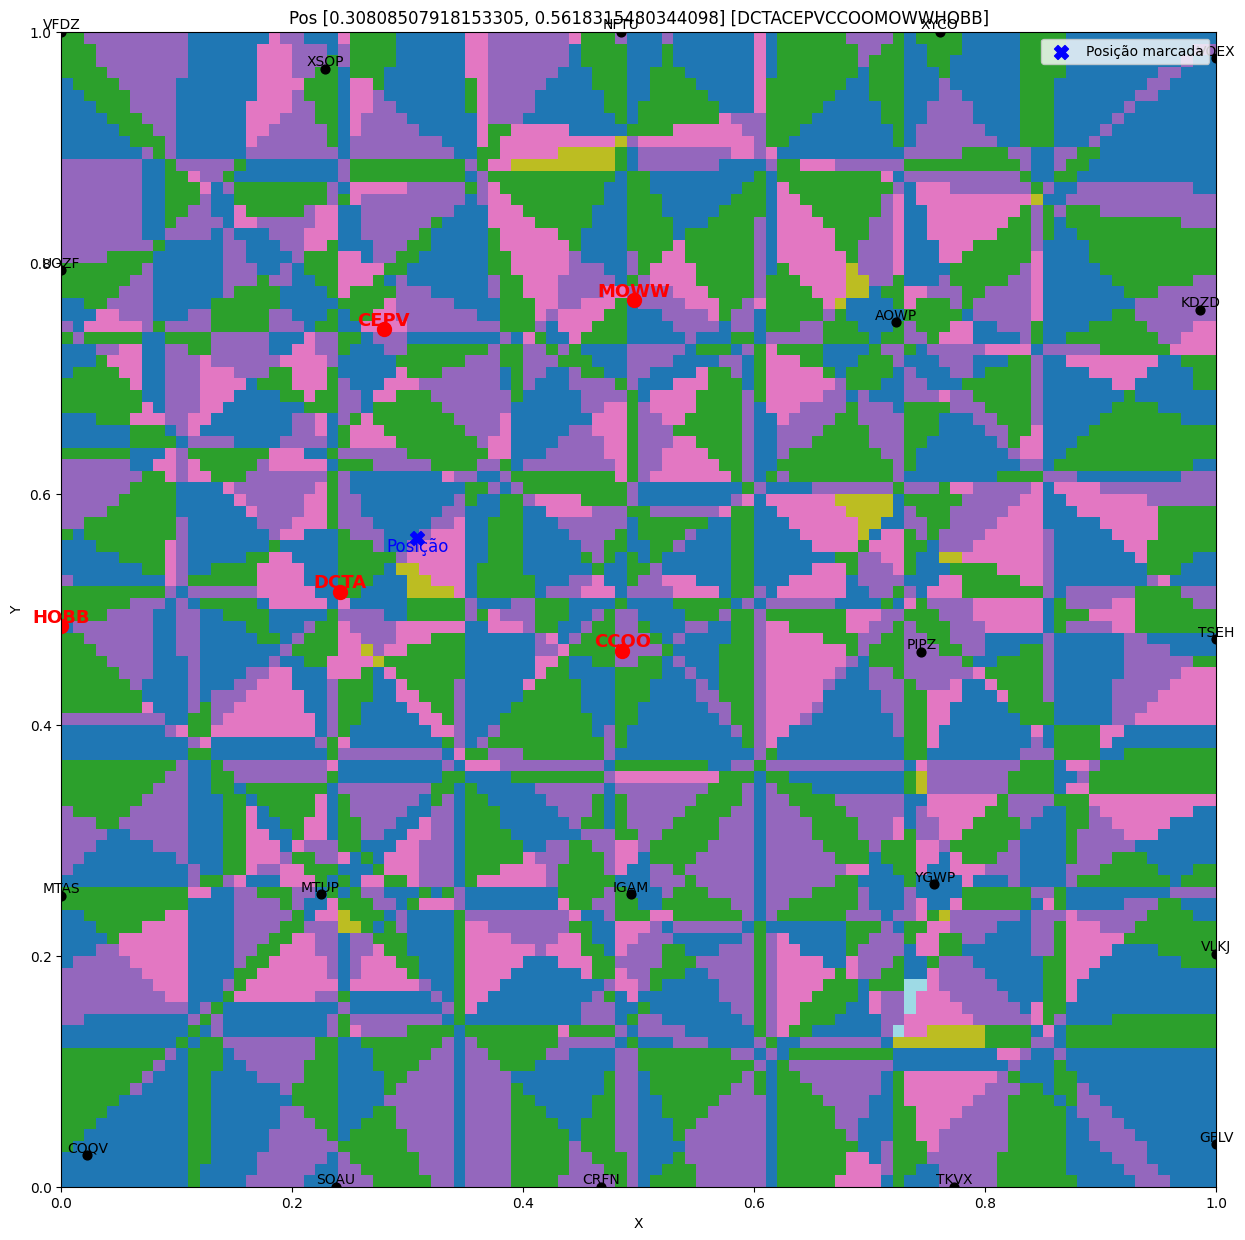

In [ ]:
pos = dfp['pos'].values[0]
nomes = dfp['position_state'].values[0]

plot_with_highlighted_position_and_names(apd, Env, posicao=pos, nomes_string=nomes)

In [89]:
dfp.head()

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,dist_to_obj_19,dist_to_obj_20,dist_to_obj_21,dist_to_obj_22,dist_to_obj_23,dist_to_obj_24,position_state,mean_distance,position_state_id,normalized_position_state_id
0,0.05,"[0.1081603832514918, 0.04361498596734858]",0.004493,"[0.07825502012911212, 0.04417973145600204]",4.664671,"[0.9364924050485655, 0.35068786019244197]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,1.157688,0.891867,0.905731,0.990191,1.132701,1.291008,COQVSOAUMTASMTUPCRFN,0.212105,224,0.234310
1,0.10,"[0.11143745714692871, 0.046544368748283174]",0.008889,"[0.06554147790873821, 0.05858765561869192]",4.309600,"[0.8863581262995255, 0.4630002936746308]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,1.153422,0.888618,0.901996,0.985967,1.128310,1.286626,COQVSOAUMTASMTUPCRFN,0.210823,224,0.234310
2,0.15,"[0.11628874546235995, 0.05045712223729988]",0.015121,"[0.09702576630862492, 0.07825506978033414]",-1.014355,"[0.8540567915661367, 0.5201797735204211]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,1.147459,0.883820,0.896549,0.979901,1.122077,1.280447,COQVSOAUMTUPMTASCRFN,0.209112,225,0.235356
3,0.20,"[0.12105150331121255, 0.054771194325561455]",0.021547,"[0.09525515697705184, 0.08628144176523148]",1.145814,"[0.819671186672009, 0.5728343091502993]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,1.141216,0.879136,0.891134,0.973743,1.115660,1.274038,COQVSOAUMTUPMTASCRFN,0.207453,225,0.235356
4,0.25,"[0.12556978085233977, 0.060432308119337155]",0.028791,"[0.09036555082254455, 0.113222275875514]",3.223861,"[0.7613447368657118, 0.6483472770413092]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,1.133995,0.874755,0.885758,0.967234,1.108583,1.266823,COQVSOAUMTUPMTASCRFN,0.205747,225,0.235356


In [103]:
# apd.head()

## get change of pos

In [165]:
dfp['last_position_state_id'] = (dfp['position_state_id'].shift(1))
dfp.shape

(72000, 86)

<Axes: >

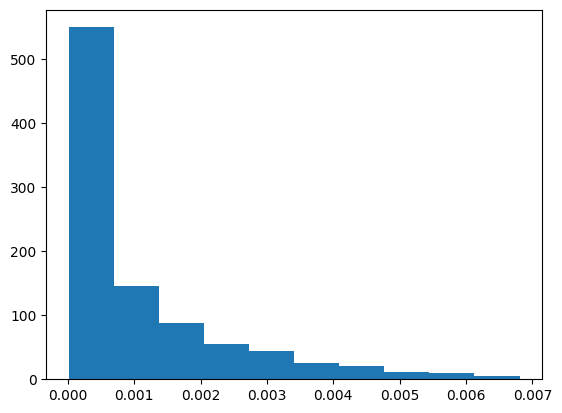

In [166]:
dfp['position_state_id'].value_counts(normalize=True,).hist(grid=False)

In [167]:
dfp[['position_state', 'position_state_id', 'last_position_state_id',]].iloc[8:12]

,position_state,position_state_id,last_position_state_id
8,SOAUCOQVMTUPMTASCRFN,789,257.0
9,SOAUCOQVMTUPMTASCRFN,789,789.0
10,SOAUCOQVMTUPMTASCRFN,789,789.0
11,SOAUMTUPCOQVMTASCRFN,797,789.0


In [168]:
dfp[['position_state_id', 'last_position_state_id']].dtypes

position_state_id           int64
last_position_state_id    float64
dtype: object

In [169]:
dfp.shape

(72000, 86)

In [170]:
len(dfp['position_state_id'])

72000

In [171]:
change_dict_ = {'change_of_position_state':[int(pos!=last_pos) for pos, last_pos in zip(dfp['position_state_id'].astype('float'), dfp['last_position_state_id'])]}
change_dict_df = pd.DataFrame(change_dict_)

print(change_dict_df.shape)
# dfp = pd.concat([dfp, change_dict_df], ignore_index=True, axis=0)

(72000, 1)


In [172]:
dfp.shape

(72000, 86)

In [173]:
dfp['change_of_position_state'] = (change_dict_df['change_of_position_state'])

In [174]:
dfp.shape

(72000, 87)

In [175]:
# dfp['change_of_position_state'].values

In [176]:
dfp[['position_state', 'position_state_id', 'last_position_state_id', 'change_of_position_state']].iloc[8:12]

,position_state,position_state_id,last_position_state_id,change_of_position_state
8,SOAUCOQVMTUPMTASCRFN,789,257.0,1
9,SOAUCOQVMTUPMTASCRFN,789,789.0,0
10,SOAUCOQVMTUPMTASCRFN,789,789.0,0
11,SOAUMTUPCOQVMTASCRFN,797,789.0,1


In [177]:
dfp[dfp['change_of_position_state'] == 1][['position_state_id', 'last_position_state_id', 'change_of_position_state']].head()

,position_state_id,last_position_state_id,change_of_position_state
0,256,NaN,1
2,257,256.0,1
8,789,257.0,1
11,797,789.0,1
12,664,797.0,1


In [178]:
dfp[dfp['change_of_position_state'] == 1].shape

(15644, 87)

In [179]:
dfp['change_of_position_state'].mean()

0.21727777777777776

# train df

In [180]:
dfc = dfp[dfp['change_of_position_state'] == 1].iloc[1:].reset_index(drop=True).copy()
dfc.shape

(15643, 87)

In [181]:
dfc.head(2)

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,dist_to_obj_21,dist_to_obj_22,dist_to_obj_23,dist_to_obj_24,position_state,mean_distance,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.15,"[0.116, 0.05]",0.015121,"[0.09702576630862492, 0.07825506978033414]",-1.014355,"[0.8540567915661367, 0.5201797735204211]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.896549,0.979901,1.122077,1.280447,COQVSOAUMTUPMTASCRFN,0.209112,257,0.268828,256.0,1
1,0.45,"[0.143, 0.092]",0.064938,"[0.10024711755413862, 0.1422307007613116]",-0.841585,"[0.5717389806063935, 0.8204355782480194]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,0.863815,0.938107,1.075179,1.231959,SOAUCOQVMTUPMTASCRFN,0.200261,789,0.825314,257.0,1


In [182]:
dfc.columns

Index(['t', 'pos', 'distance_travelled', 'vel', 'rot_vel', 'head_direction',
       'obj_0_pos', 'obj_0_name', 'obj_1_pos', 'obj_1_name', 'obj_2_pos',
       'obj_2_name', 'obj_3_pos', 'obj_3_name', 'obj_4_pos', 'obj_4_name',
       'obj_5_pos', 'obj_5_name', 'obj_6_pos', 'obj_6_name', 'obj_7_pos',
       'obj_7_name', 'obj_8_pos', 'obj_8_name', 'obj_9_pos', 'obj_9_name',
       'obj_10_pos', 'obj_10_name', 'obj_11_pos', 'obj_11_name', 'obj_12_pos',
       'obj_12_name', 'obj_13_pos', 'obj_13_name', 'obj_14_pos', 'obj_14_name',
       'obj_15_pos', 'obj_15_name', 'obj_16_pos', 'obj_16_name', 'obj_17_pos',
       'obj_17_name', 'obj_18_pos', 'obj_18_name', 'obj_19_pos', 'obj_19_name',
       'obj_20_pos', 'obj_20_name', 'obj_21_pos', 'obj_21_name', 'obj_22_pos',
       'obj_22_name', 'obj_23_pos', 'obj_23_name', 'obj_24_pos', 'obj_24_name',
       'dist_to_obj_0', 'dist_to_obj_1', 'dist_to_obj_2', 'dist_to_obj_3',
       'dist_to_obj_4', 'dist_to_obj_5', 'dist_to_obj_6', 'dist_to_obj_7'

In [183]:
columns_to_keep = [
    't',
    'pos',
    'distance_travelled',
    'vel',
    'rot_vel',
    'head_direction',
    'position_state',
    'position_state_id',
    'normalized_position_state_id',
    'last_position_state_id',
    'change_of_position_state',
]

In [184]:
# print(dfc[columns_to_keep].shape)
dfc[columns_to_keep].to_parquet(r'/home/mgteus/workspace/navitrans/bert_trainset_squared_25.gzip', index=False)

In [ ]:
# apd.to_parquet(r'apd.gzip')

In [109]:
dfc[columns_to_keep].head(5)

,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.15,"[0.11628874546235995, 0.05045712223729988]",0.015121,"[0.09702576630862492, 0.07825506978033414]",-1.014355,"[0.8540567915661367, 0.5201797735204211]",COQVSOAUMTUPMTASCRFN,225,0.235356,224.0,1
1,0.45,"[0.14319002726063726, 0.09185130387891463]",0.064938,"[0.10024711755413862, 0.1422307007613116]",-0.841585,"[0.5717389806063935, 0.8204355782480194]",SOAUCOQVMTUPMTASCRFN,706,0.738494,225.0,1
2,0.60,"[0.15578573223583697, 0.11874133335991428]",0.094643,"[0.0798589049301679, 0.17495554788286072]",-0.420359,"[0.46461453149961945, 0.8855130361092315]",SOAUMTUPCOQVMTASCRFN,713,0.745816,706.0,1
3,0.65,"[0.15887096033589218, 0.12852274588099186]",0.104899,"[0.06170456200110419, 0.19562825042155146]",2.453329,"[0.4114542821866489, 0.911430399794888]",MTUPSOAUCOQVMTASCRFN,600,0.627615,713.0,1
4,0.80,"[0.16435475418080597, 0.15939373276094693]",0.136306,"[0.04106226127052637, 0.2200733359869167]",-1.797005,"[0.24133630336286144, 0.9704415431540164]",MTUPSOAUMTASCOQVIGAM,611,0.639121,600.0,1


In [107]:
dfc['position_state'].values[:3]

array(['VJRDXWOIAVCHDOVEZJSP', 'XWOIVJRDAVCHDOVEDZGU',
       'XWOIAVCHVJRDDOVEDZGU'], dtype=object)

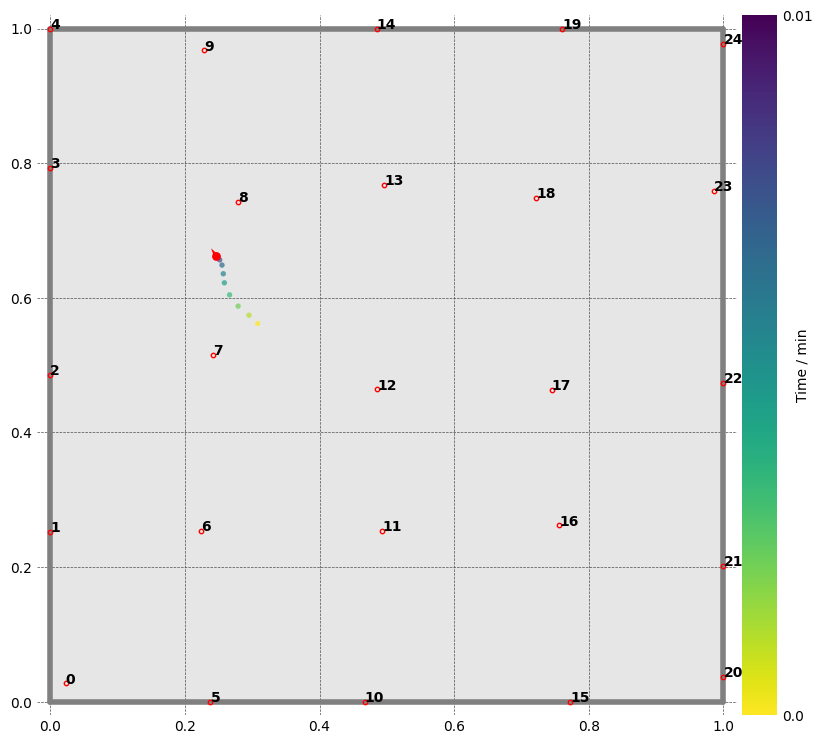

In [116]:
fig, ax = plt.subplots(1, 1, figsize=(14,7))
for i in range(NUM_OF_CUES):
    plt.annotate(text=i, xy=Env.objects['objects'][i], fontsize=10, fontweight='bold')
ax = Ag.plot_trajectory(color='changing', colorbar=True, gridlines=True,fig=fig, ax=ax, t_start=0, t_end=dfc['t'].values[5])

plt.show()

/tmp/ipykernel_51651/1370218860.py:55: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab20', max_color)


{'HOBB', 'MOWW', 'CCOO', 'CEPV', 'DCTA'}


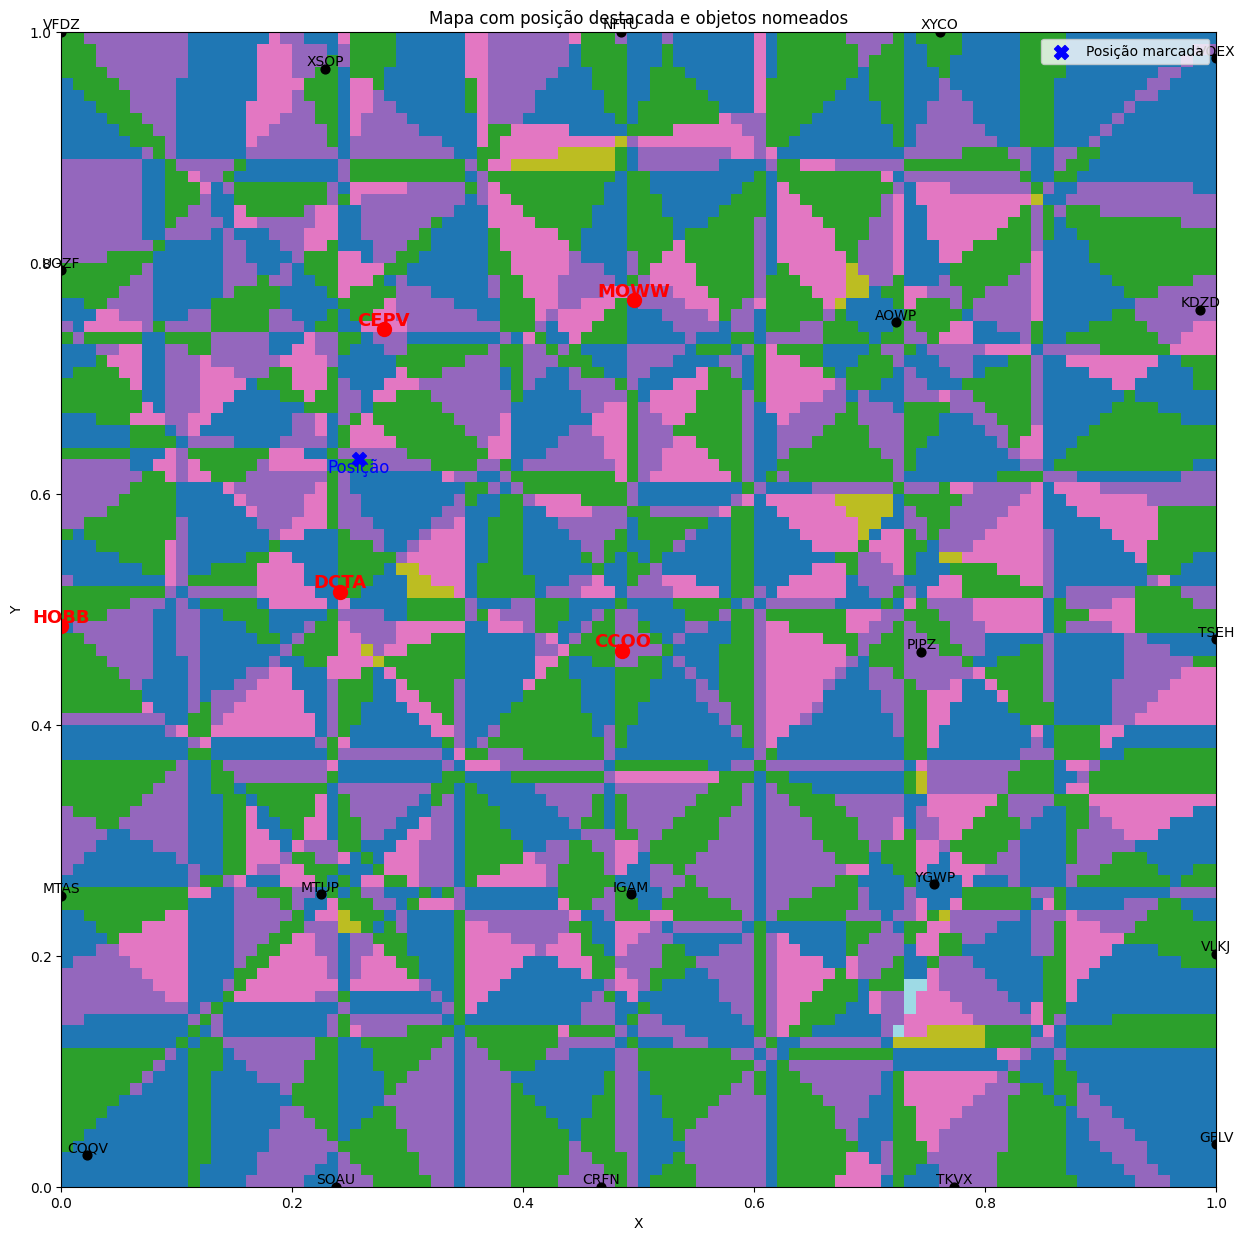

In [121]:
pos = dfc['pos'].values[0]
nomes = dfc['position_state'].values[0]

plot_with_highlighted_position_and_names(apd, Env, posicao=pos, nomes_string=nomes)

/tmp/ipykernel_51651/1370218860.py:55: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab20', max_color)


{'UOZF', 'MOWW', 'CCOO', 'CEPV', 'DCTA'}


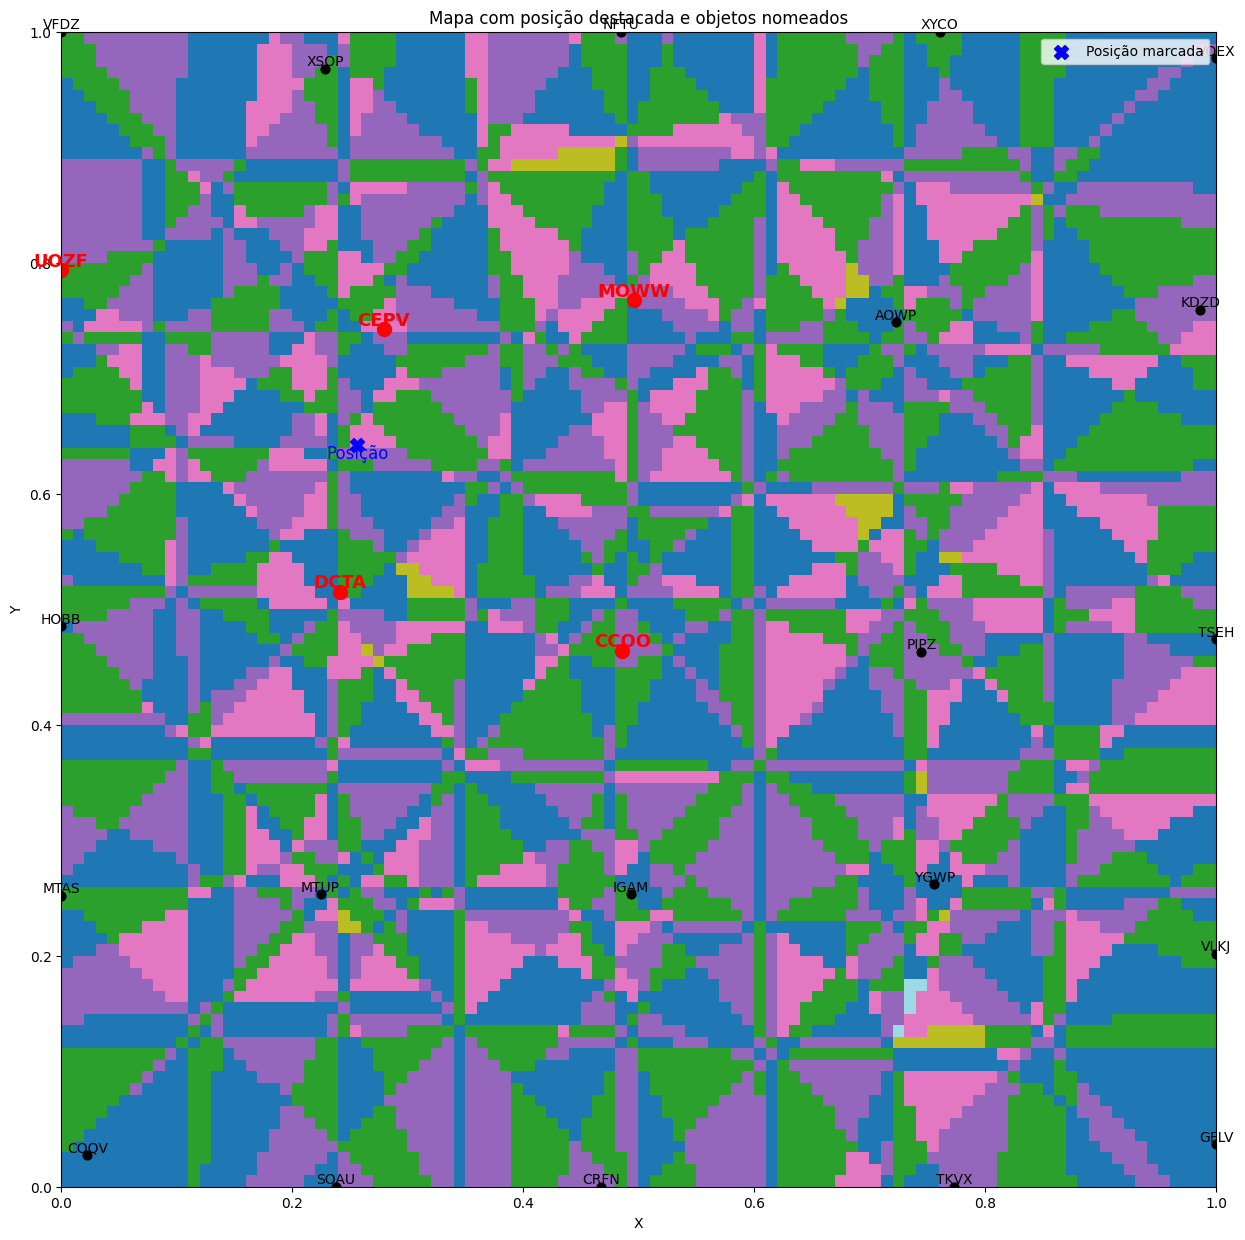

In [122]:
pos = dfc['pos'].values[1]
nomes = dfc['position_state'].values[1]

plot_with_highlighted_position_and_names(apd, Env, posicao=pos, nomes_string=nomes)

# FIM

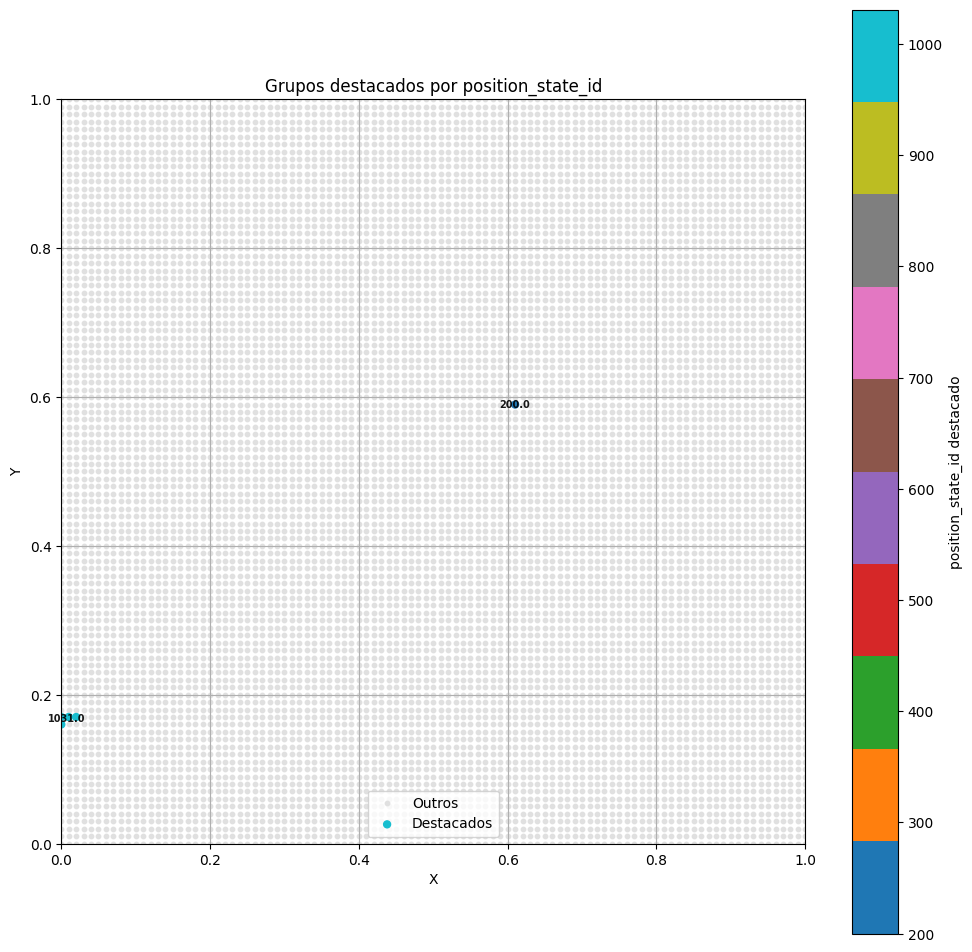

In [ ]:
grupos_para_destacar = [1031,200]
plot_position_states(apd, grupos_para_destacar)

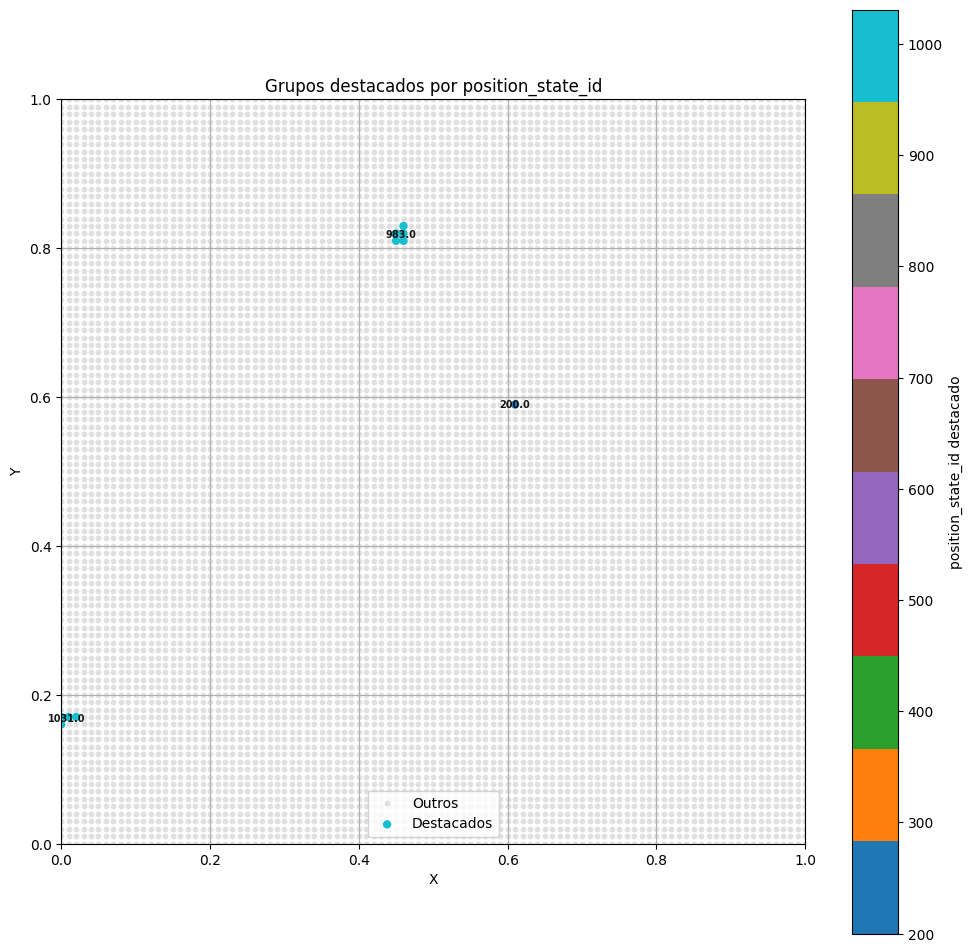

In [98]:
grupos_para_destacar = [200, 983, 1031]
plot_position_states(apd, grupos_para_destacar)

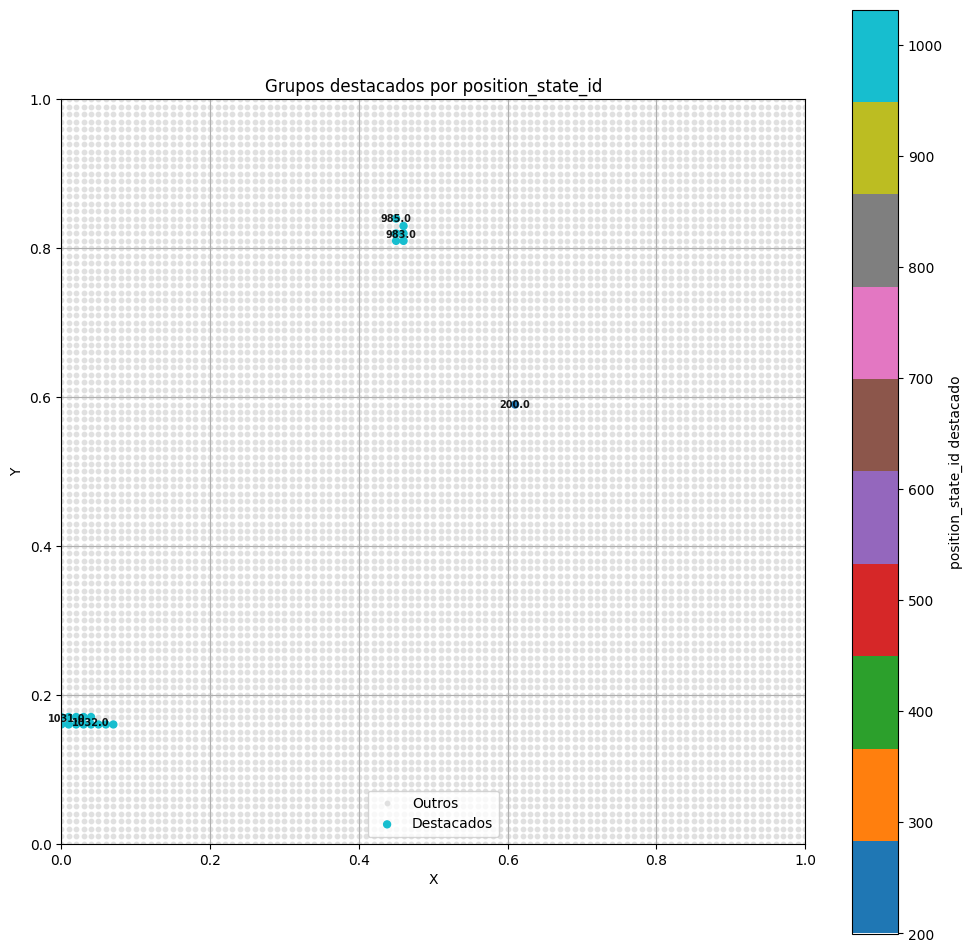

In [99]:
grupos_para_destacar = [200, 985, 983, 1032, 1031]
plot_position_states(apd, grupos_para_destacar)

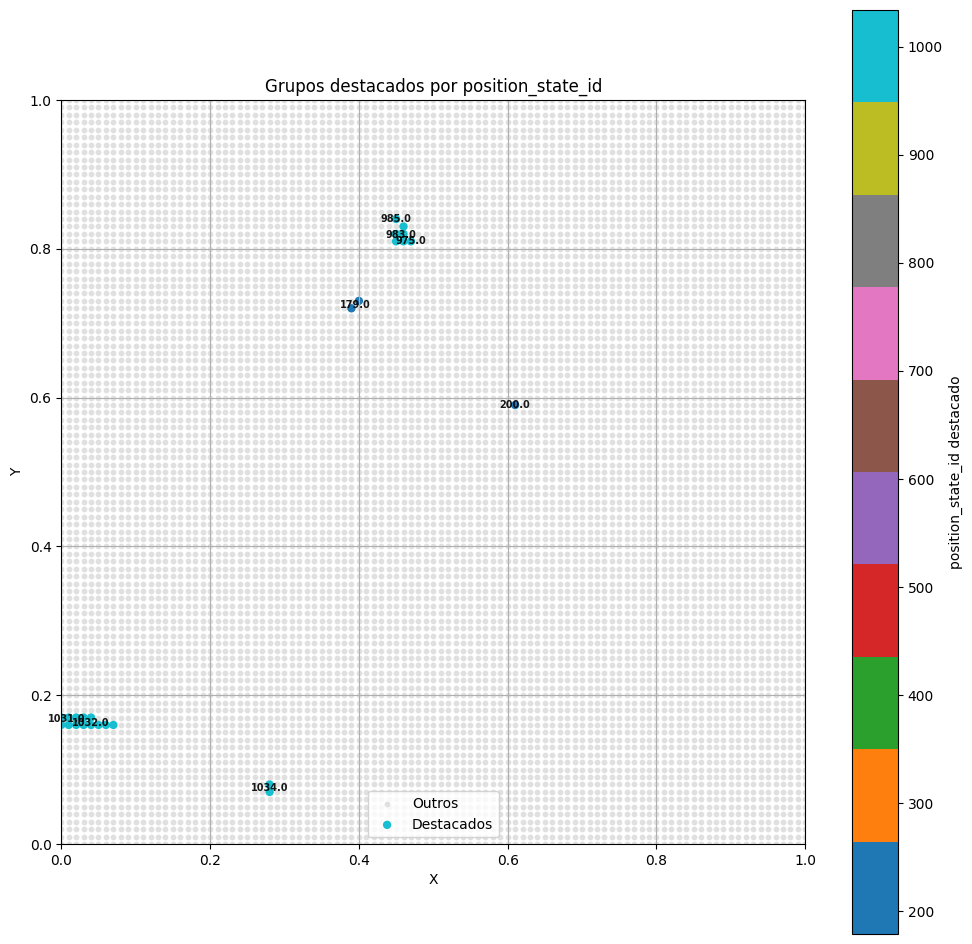

In [100]:
grupos_para_destacar = [200, 179, 985, 975, 983, 1031, 1032, 1034, 1031]
plot_position_states(apd, grupos_para_destacar)

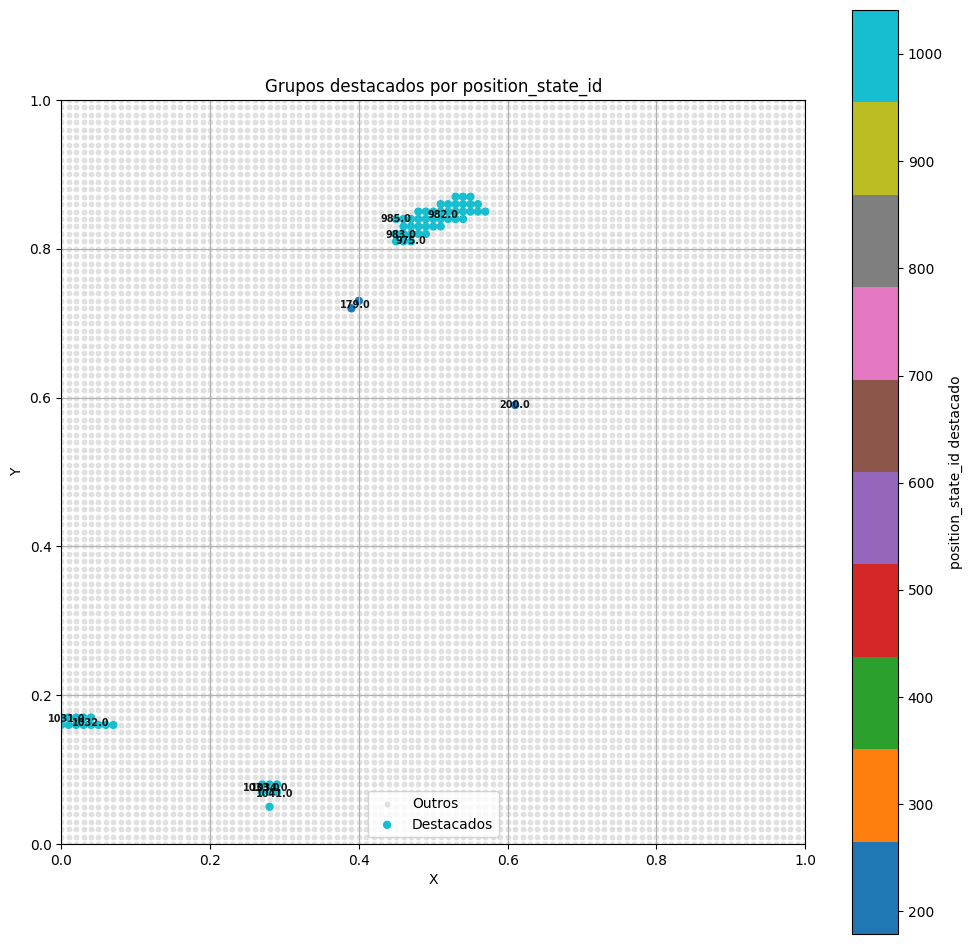

In [101]:
grupos_para_destacar = [200, 1747, 179, 983, 985, 983, 975, 982, 983, 1032, 1031, 1034, 1032, 1033, 1034, 1041, 1031]
plot_position_states(apd, grupos_para_destacar)

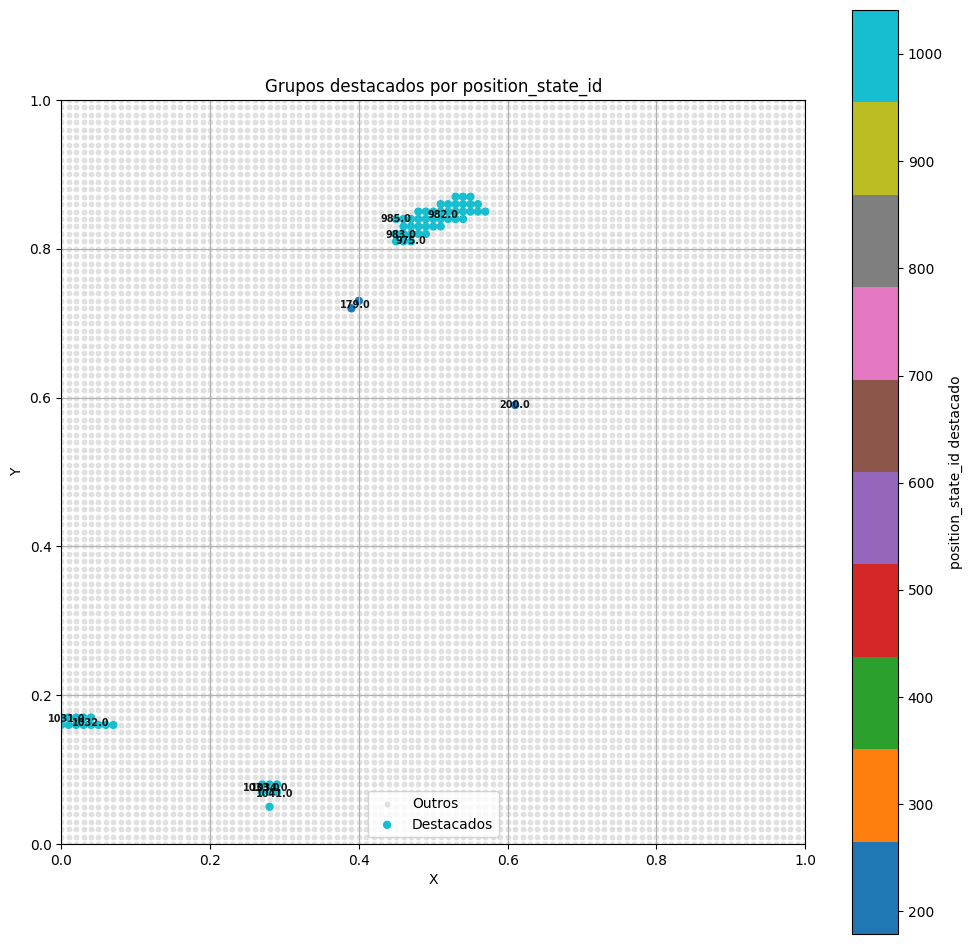

In [102]:
grupos_para_destacar = [200, 1747, 179, 983, 985, 983, 975, 982, 983, 1032, 1031, 1034, 1032, 1033, 1034, 1041, 1031]
plot_position_states(apd, grupos_para_destacar)